In [1]:
!pip install -q kaggle tensorflow pandas numpy matplotlib seaborn pillow scikit-learn

In [2]:
import os
import random
import shutil
import subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

DATA_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directories created!")
print(PROJECT_DIR)

Project directories created!
/content/drive/MyDrive/Waste_Classification


In [5]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [6]:
KAGGLE_DIR = Path("/root/.kaggle")
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    KAGGLE_DIR / "kaggle.json"
)

os.chmod(KAGGLE_DIR / "kaggle.json", 0o600)

print("Kaggle authentication configured!")

Kaggle authentication configured!


In [7]:
dataset_zip_dir = Path("/content/kaggle_download")
dataset_zip_dir.mkdir(exist_ok=True)

subprocess.run(
    [
        "kaggle",
        "datasets",
        "download",
        "-d",
        "asdasdasasdas/garbage-classification",
        "-p",
        str(dataset_zip_dir)
    ],
    check=True
)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [9]:
import zipfile

zip_files = list(dataset_zip_dir.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("Kaggle dataset ZIP was not found.")

for zip_file in zip_files:
    with zipfile.ZipFile(zip_file, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("Dataset extracted successfully!")

KeyboardInterrupt: 

In [10]:
CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

def find_dataset_root(base_path):
    candidates = []

    for root, dirs, files in os.walk(base_path):
        folder_names = {
            d.lower() for d in dirs
        }

        if set(CLASSES).issubset(folder_names):
            candidates.append(Path(root))

    if not candidates:
        raise FileNotFoundError(
            "Could not find all six class folders. "
            "Inspect the extracted dataset structure."
        )

    return max(candidates, key=lambda p: len(p.parts))


DATASET_ROOT = find_dataset_root(DATA_DIR)

print("Dataset root:", DATASET_ROOT)

for class_name in CLASSES:
    print(class_name, "->", DATASET_ROOT / class_name)

Dataset root: /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification
cardboard -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/cardboard
glass -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/glass
metal -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/metal
paper -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/paper
plastic -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/plastic
trash -> /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification/trash


In [11]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

class_counts = {}

for class_name in CLASSES:

    class_path = DATASET_ROOT / class_name

    images = [
        file for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts[class_name] = len(images)


dataset_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Category", "Image Count"]
)

print("Dataset Summary:")
display(dataset_df)

print("\nTotal Images:", sum(class_counts.values()))

Dataset Summary:


,Category,Image Count
0,cardboard,403
1,glass,501
2,metal,410
3,paper,594
4,plastic,482
5,trash,137



Total Images: 2527


In [12]:
valid_images = []
corrupted_images = []

for class_name in CLASSES:

    class_path = DATASET_ROOT / class_name

    for image_path in class_path.rglob("*"):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                width, height = img.size

            valid_images.append({
                "image_path": str(image_path),
                "category": class_name,
                "width": width,
                "height": height
            })

        except Exception:
            corrupted_images.append(str(image_path))


manifest_df = pd.DataFrame(valid_images)

manifest_df.to_csv(
    OUTPUT_DIR / "dataset_manifest.csv",
    index=False
)

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

print("\nManifest saved successfully!")

Valid images: 2526
Corrupted images: 1

Manifest saved successfully!


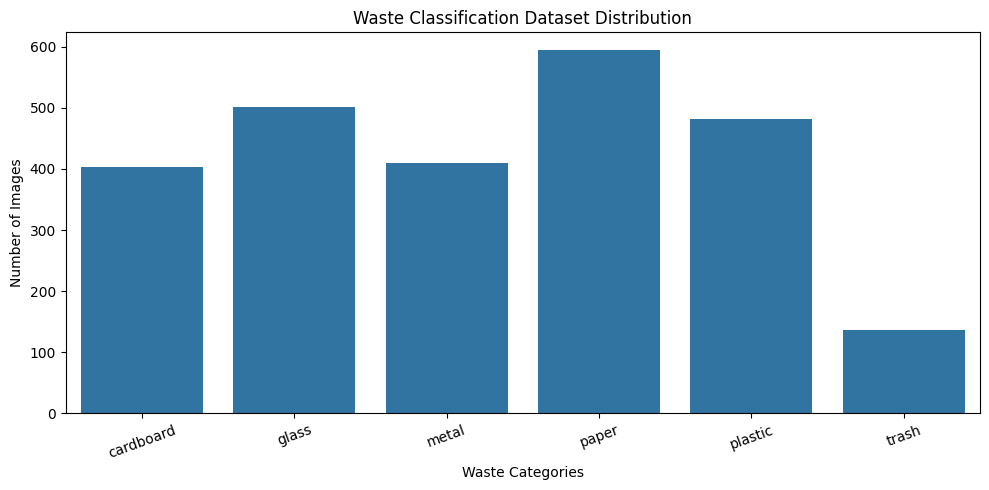

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=dataset_df,
    x="Category",
    y="Image Count"
)

plt.title("Waste Classification Dataset Distribution")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "class_distribution.png",
    dpi=300
)

plt.show()

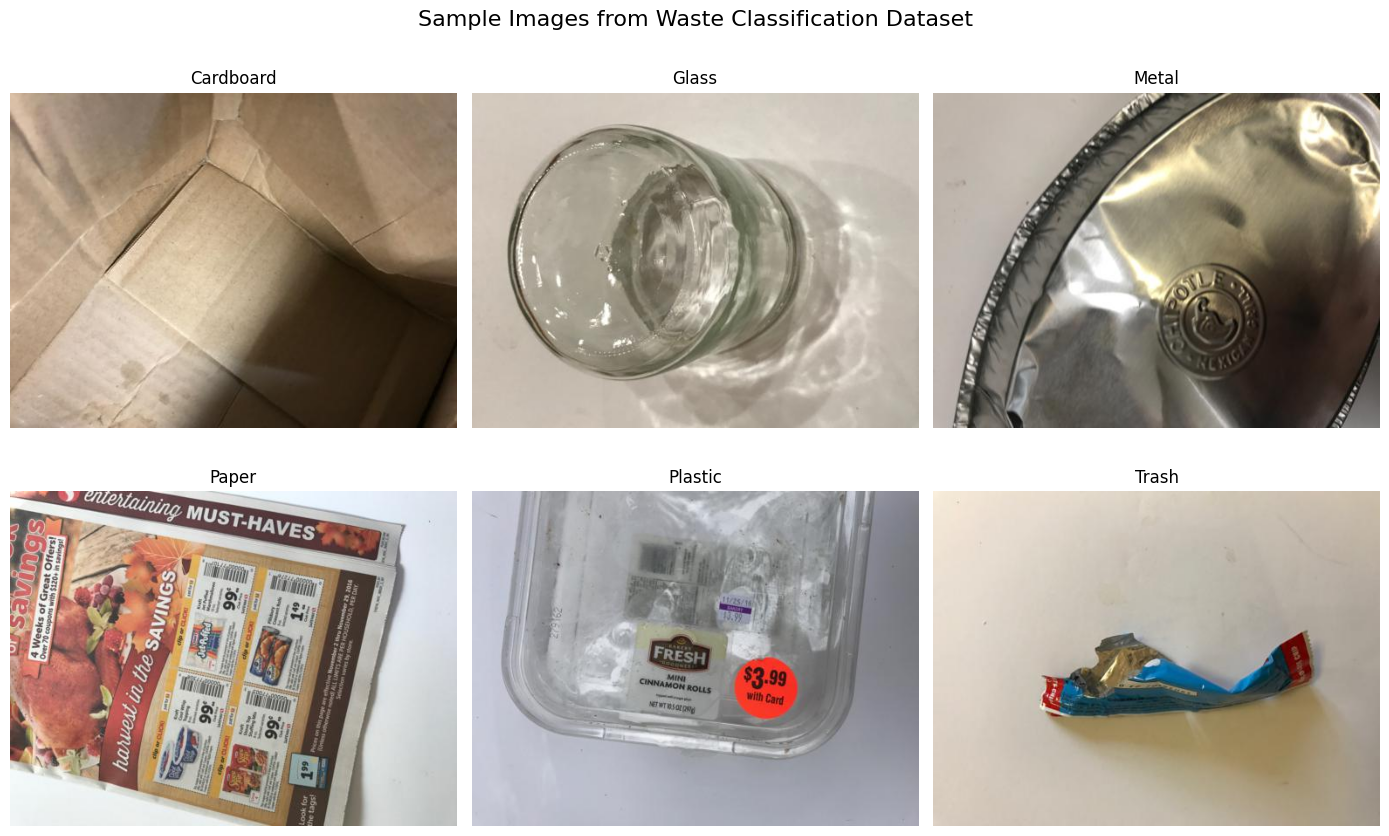

In [14]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 9)
)

for i, class_name in enumerate(CLASSES):

    class_path = DATASET_ROOT / class_name

    image_files = [
        p for p in class_path.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    sample_path = random.choice(image_files)

    img = Image.open(sample_path).convert("RGB")

    ax = axes[i // 3, i % 3]

    ax.imshow(img)
    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.suptitle(
    "Sample Images from Waste Classification Dataset",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sample_images.png",
    dpi=300
)

plt.show()

Image Dimensions Summary:


,width,height
count,2526.0,2526.0
mean,512.0,384.0
std,0.0,0.0
min,512.0,384.0
25%,512.0,384.0
50%,512.0,384.0
75%,512.0,384.0
max,512.0,384.0


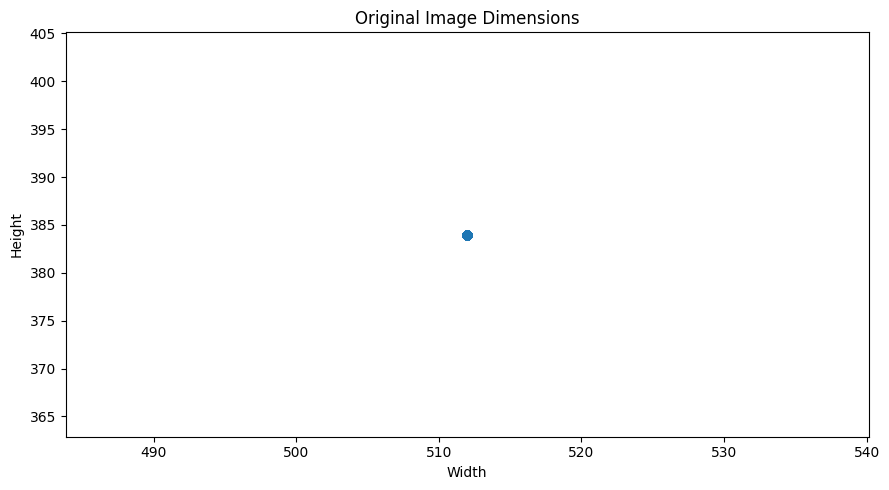

In [15]:
print("Image Dimensions Summary:")

display(
    manifest_df[
        ["width", "height"]
    ].describe()
)

plt.figure(figsize=(9, 5))

plt.scatter(
    manifest_df["width"],
    manifest_df["height"],
    alpha=0.5
)

plt.title("Original Image Dimensions")
plt.xlabel("Width")
plt.ylabel("Height")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "image_dimensions.png",
    dpi=300
)

plt.show()

In [16]:
print("=" * 50)
print("WASTE CLASSIFICATION - STAGE 1 REPORT")
print("=" * 50)

print("Dataset location:", DATASET_ROOT)
print("Total valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))
print("Number of categories:", len(CLASSES))

print("\nClass Distribution:")

for category in CLASSES:
    count = sum(
        1 for item in valid_images
        if item["category"] == category
    )
    print(f"{category:12s}: {count}")

print("\nGenerated Files:")

for file in OUTPUT_DIR.iterdir():
    print("-", file.name)

print("\nSTAGE 1 COMPLETED!")

WASTE CLASSIFICATION - STAGE 1 REPORT
Dataset location: /content/drive/MyDrive/Waste_Classification/dataset/Garbage classification/Garbage classification
Total valid images: 2526
Corrupted images: 1
Number of categories: 6

Class Distribution:
cardboard   : 403
glass       : 501
metal       : 410
paper       : 594
plastic     : 481
trash       : 137

Generated Files:
- class_distribution.png
- sample_images.png
- dataset_manifest.csv
- image_dimensions.png

STAGE 1 COMPLETED!


# Stage 2

In [17]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Project paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

DATA_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Original dataset location from Stage 1
DATASET_ROOT = (
    DATA_DIR /
    "Garbage_classification" /
    "Garbage classification"
)

# If your folder name differs, use the DATASET_ROOT
# variable already discovered in Stage 1 instead.

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

TensorFlow version: 2.21.0
Dataset root: /content/drive/MyDrive/Waste_Classification/dataset/Garbage_classification/Garbage classification
Dataset exists: False


In [18]:
MANIFEST_PATH = OUTPUT_DIR / "dataset_manifest.csv"

manifest_df = pd.read_csv(MANIFEST_PATH)

# Verify required columns
required_columns = [
    "image_path",
    "category",
    "width",
    "height"
]

assert all(
    col in manifest_df.columns
    for col in required_columns
), "Manifest columns are missing!"

# Keep only our six categories
manifest_df = manifest_df[
    manifest_df["category"].isin(CLASSES)
].copy()

# Remove any missing files
manifest_df = manifest_df[
    manifest_df["image_path"].apply(
        lambda x: Path(x).is_file()
    )
].reset_index(drop=True)

print("Total validated images:", len(manifest_df))
print("\nImages per category:")
print(manifest_df["category"].value_counts().reindex(CLASSES))

Total validated images: 2526

Images per category:
category
cardboard    403
glass        501
metal        410
paper        594
plastic      481
trash        137
Name: count, dtype: int64


In [19]:
train_df, temp_df = train_test_split(
    manifest_df,
    test_size=0.30,
    random_state=SEED,
    stratify=manifest_df["category"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["category"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("DATASET SPLIT SUMMARY")
print("-" * 40)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Total:", len(train_df) + len(val_df) + len(test_df))

DATASET SPLIT SUMMARY
----------------------------------------
Training images: 1768
Validation images: 379
Testing images: 379
Total: 2526


           Training  Validation  Testing
category                                
cardboard       282          61       60
glass           350          75       76
metal           287          62       61
paper           416          89       89
plastic         337          72       72
trash            96          20       21


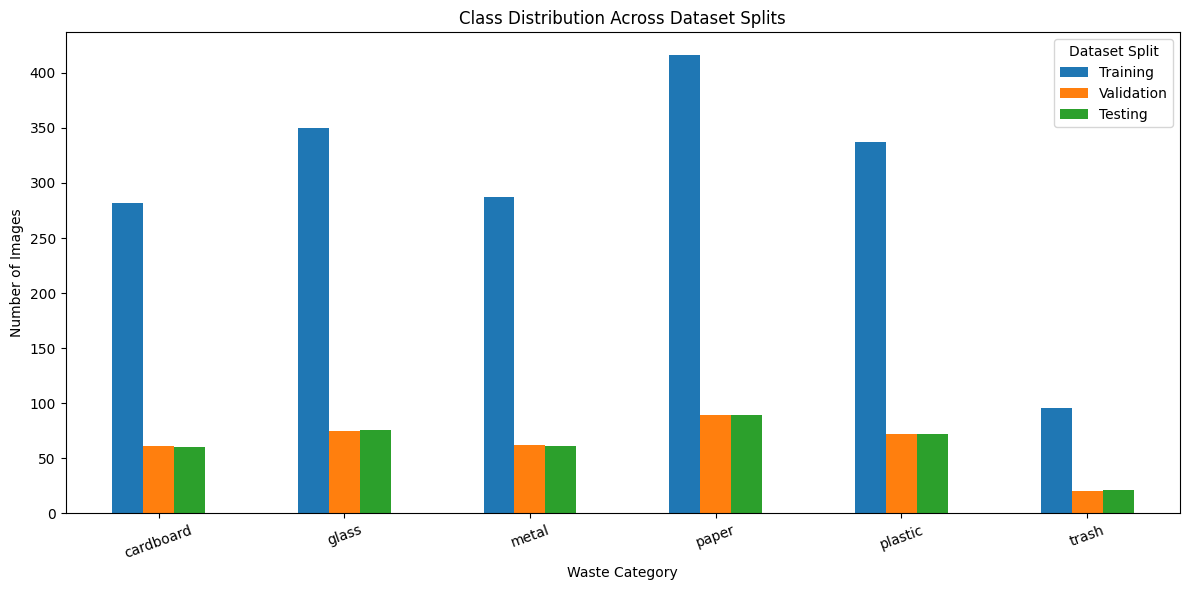

In [20]:
distribution = pd.DataFrame({
    "Training": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Testing": test_df["category"].value_counts()
}).reindex(CLASSES).fillna(0).astype(int)

print(distribution)

distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.legend(title="Dataset Split")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "split_distribution.png",
    dpi=300
)

plt.show()

In [21]:
SPLIT_DIR = OUTPUT_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(
    SPLIT_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    SPLIT_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    SPLIT_DIR / "test.csv",
    index=False
)

print("Dataset splits saved successfully!")

for file in SPLIT_DIR.iterdir():
    print(file.name)

Dataset splits saved successfully!
train.csv
validation.csv
test.csv


In [22]:
CLASS_TO_INDEX = {
    category: index
    for index, category in enumerate(CLASSES)
}

INDEX_TO_CLASS = {
    index: category
    for category, index in CLASS_TO_INDEX.items()
}

for df in [train_df, val_df, test_df]:
    df["label"] = df["category"].map(CLASS_TO_INDEX)

print(CLASS_TO_INDEX)

{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [23]:
import json

with open(OUTPUT_DIR / "class_mapping.json", "w") as f:
    json.dump(CLASS_TO_INDEX, f, indent=4)

print("Class mapping saved!")

Class mapping saved!


In [24]:
def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [25]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.08
    ),

    tf.keras.layers.RandomZoom(
        0.10
    ),

    tf.keras.layers.RandomContrast(
        0.10
    )

], name="data_augmentation")

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [26]:
AUTOTUNE = tf.data.AUTOTUNE

def create_tf_dataset(df, training=False):

    image_paths = df["image_path"].values

    labels = df["label"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda x, y: (
                data_augmentation(x, training=True),
                y
            ),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


train_ds = create_tf_dataset(
    train_df,
    training=True
)

val_ds = create_tf_dataset(
    val_df,
    training=False
)

test_ds = create_tf_dataset(
    test_df,
    training=False
)

print("TensorFlow datasets created successfully!")

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

TensorFlow datasets created successfully!
Training batches: 56
Validation batches: 12
Testing batches: 12


In [27]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"].values
)

CLASS_WEIGHTS = {
    index: float(weight)
    for index, weight in enumerate(class_weights_array)
}

print("CLASS WEIGHTS")
print("-" * 35)

for index, weight in CLASS_WEIGHTS.items():
    print(f"{INDEX_TO_CLASS[index]:12s}: {weight:.4f}")

CLASS WEIGHTS
-----------------------------------
cardboard   : 1.0449
glass       : 0.8419
metal       : 1.0267
paper       : 0.7083
plastic     : 0.8744
trash       : 3.0694


In [28]:
with open(OUTPUT_DIR / "class_weights.json", "w") as f:

    json.dump(
        {
            INDEX_TO_CLASS[k]: v
            for k, v in CLASS_WEIGHTS.items()
        },
        f,
        indent=4
    )

print("Class weights saved successfully!")

Class weights saved successfully!


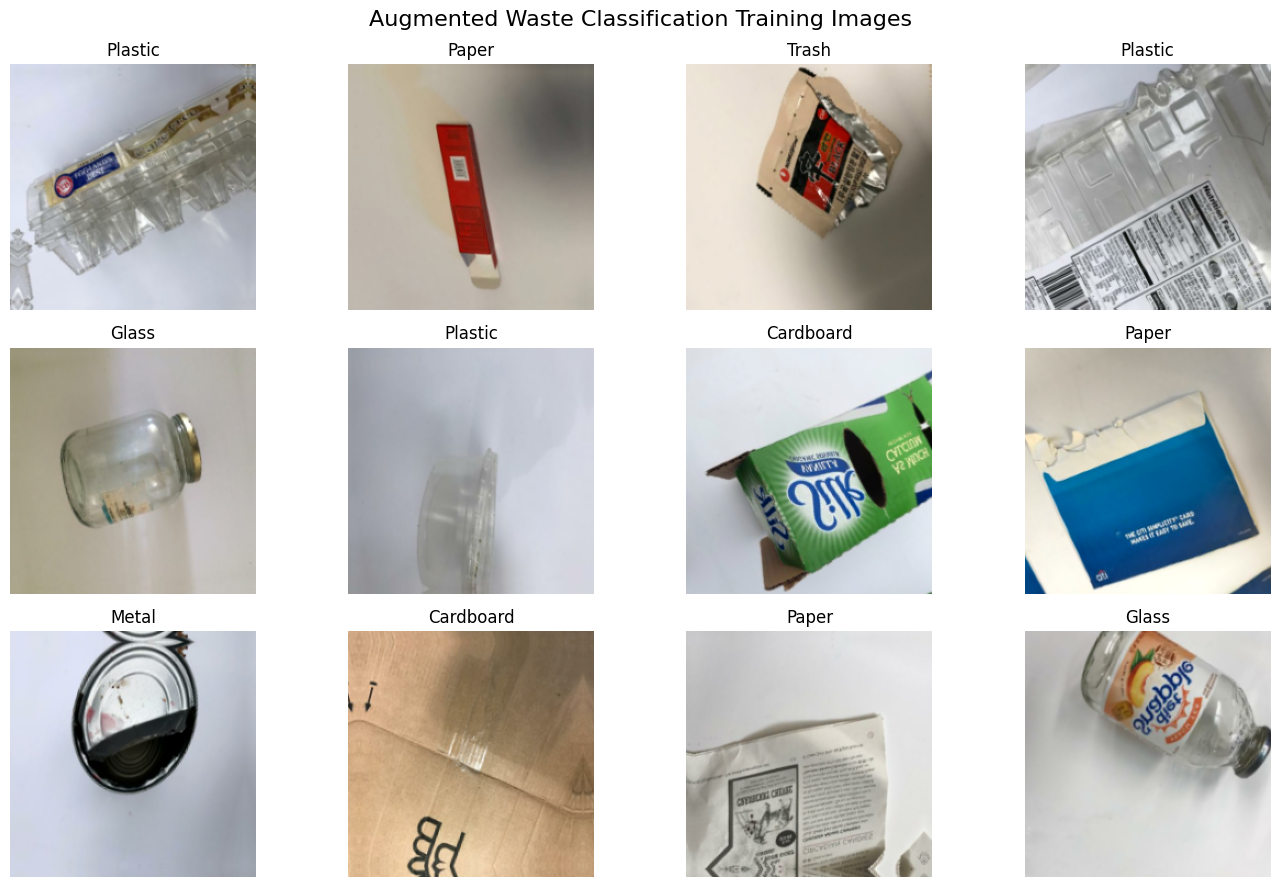

In [29]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(14, 9))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())

    label = labels[i].numpy()

    plt.title(INDEX_TO_CLASS[int(label)].capitalize())

    plt.axis("off")

plt.suptitle(
    "Augmented Waste Classification Training Images",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "augmented_samples.png",
    dpi=300
)

plt.show()

In [30]:
sample_images, sample_labels = next(iter(train_ds))

print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)

print(
    "Minimum pixel value:",
    tf.reduce_min(sample_images).numpy()
)

print(
    "Maximum pixel value:",
    tf.reduce_max(sample_images).numpy()
)

print(
    "Unique labels:",
    np.unique(sample_labels.numpy())
)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0389817
Unique labels: [0 1 2 3 4 5]


In [31]:
stage2_config = {
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "classes": CLASSES,
    "class_mapping": CLASS_TO_INDEX,
    "split_ratios": {
        "training": 0.70,
        "validation": 0.15,
        "testing": 0.15
    },
    "normalization": "pixel_values_divided_by_255",
    "augmentation": [
        "horizontal_flip",
        "rotation",
        "zoom",
        "contrast"
    ],
    "class_balancing": "balanced_class_weights"
}

with open(OUTPUT_DIR / "stage2_config.json", "w") as f:
    json.dump(stage2_config, f, indent=4)

print("Stage 2 configuration saved!")

Stage 2 configuration saved!


In [32]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 2 REPORT")
print("=" * 55)

print(f"Total images:      {len(manifest_df)}")
print(f"Training images:   {len(train_df)}")
print(f"Validation images: {len(val_df)}")
print(f"Testing images:    {len(test_df)}")

print("\nImage configuration:")
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", len(CLASSES))

print("\nClass distribution:")
print(distribution)

print("\nGenerated files:")

for file in OUTPUT_DIR.rglob("*"):
    if file.is_file():
        print("-", file.relative_to(PROJECT_DIR))

print("\n" + "=" * 55)
print("STAGE 2 COMPLETED SUCCESSFULLY!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 2 REPORT
Total images:      2526
Training images:   1768
Validation images: 379
Testing images:    379

Image configuration:
Image size: (224, 224)
Batch size: 32
Number of classes: 6

Class distribution:
           Training  Validation  Testing
category                                
cardboard       282          61       60
glass           350          75       76
metal           287          62       61
paper           416          89       89
plastic         337          72       72
trash            96          20       21

Generated files:
- outputs/class_distribution.png
- outputs/sample_images.png
- outputs/dataset_manifest.csv
- outputs/image_dimensions.png
- outputs/split_distribution.png
- outputs/class_mapping.json
- outputs/class_weights.json
- outputs/augmented_samples.png
- outputs/stage2_config.json
- outputs/splits/train.csv
- outputs/splits/validation.csv
- outputs/splits/test.csv

STAGE 2 COMPLETED SUCCESSFULLY!


In [33]:
# Reload the original Stage 1 manifest
original_manifest = pd.read_csv(
    OUTPUT_DIR / "dataset_manifest.csv"
)

print("Original manifest:", len(original_manifest))
print("Current manifest:", len(manifest_df))

# Identify missing image files
missing_images = original_manifest[
    ~original_manifest["image_path"].apply(
        lambda x: Path(x).is_file()
    )
]

print("\nMissing images:", len(missing_images))

if len(missing_images) > 0:
    display(missing_images)
else:
    print("All image files are accessible!")

Original manifest: 2526
Current manifest: 2526

Missing images: 0
All image files are accessible!


# Stage 3

In [34]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("\nGPU detected!")
    for gpu in gpus:
        print(gpu)
else:
    print("\nNo GPU detected. Training will use CPU.")

TensorFlow Version: 2.21.0

GPU detected!
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [35]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

print("CNN training libraries imported successfully!")

CNN training libraries imported successfully!


In [36]:
IMG_SIZE = (224, 224)
NUM_CLASSES = 6
EPOCHS = 30
BATCH_SIZE = 32

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model configuration ready!")

Model configuration ready!


In [37]:
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

print("Class weights:", CLASS_WEIGHTS)

Training batches: 56
Validation batches: 12
Testing batches: 12
Class weights: {0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


In [38]:
def build_cnn_model():

    model = models.Sequential([

        # Input
        layers.Input(shape=(224, 224, 3)),

        # Block 1
        layers.Conv2D(
            32, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(
            64, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(
            128, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Block 4
        layers.Conv2D(
            256, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),

        # Classification head
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.40),

        # Output
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )

    ], name="Custom_Waste_CNN")

    return model


cnn_model = build_cnn_model()

print("Custom CNN created successfully!")

cnn_model.summary()

Custom CNN created successfully!


Model: "Custom_Waste_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [39]:
cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("CNN compiled successfully!")

CNN compiled successfully!


In [40]:
checkpoint_path = MODEL_DIR / "cnn_best.keras"

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "cnn_training_history.csv")
    )

]

print("Training callbacks configured!")

Training callbacks configured!


In [41]:
cnn_history = cnn_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    class_weight=CLASS_WEIGHTS,

    callbacks=callbacks,

    verbose=1

)

print("CNN training completed!")

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3903 - loss: 1.6288   
Epoch 1: val_loss improved from None to 1.86756, saving model to /content/drive/MyDrive/Waste_Classification/models/cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/cnn_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.4406 - loss: 1.5138 - val_accuracy: 0.2322 - val_loss: 1.8676 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step - accuracy: 0.5281 - loss: 1.2438
Epoch 2: val_loss did not improve from 1.86756
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 526ms/step - accuracy: 0.5170 - loss: 1.2807 - val_accuracy: 0.0528 - val_loss: 2.0784 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.5228 - loss: 1.2609
Epoch 3: val_loss did not improve from 1.86756
56/56 ━━━━━━━━━━━━━━━━━━━━ 41s 524ms/step - accuracy: 0.5390 - loss: 1.2164 - val_accuracy: 0.0528 - val_loss: 2.0764 - learning_rate:

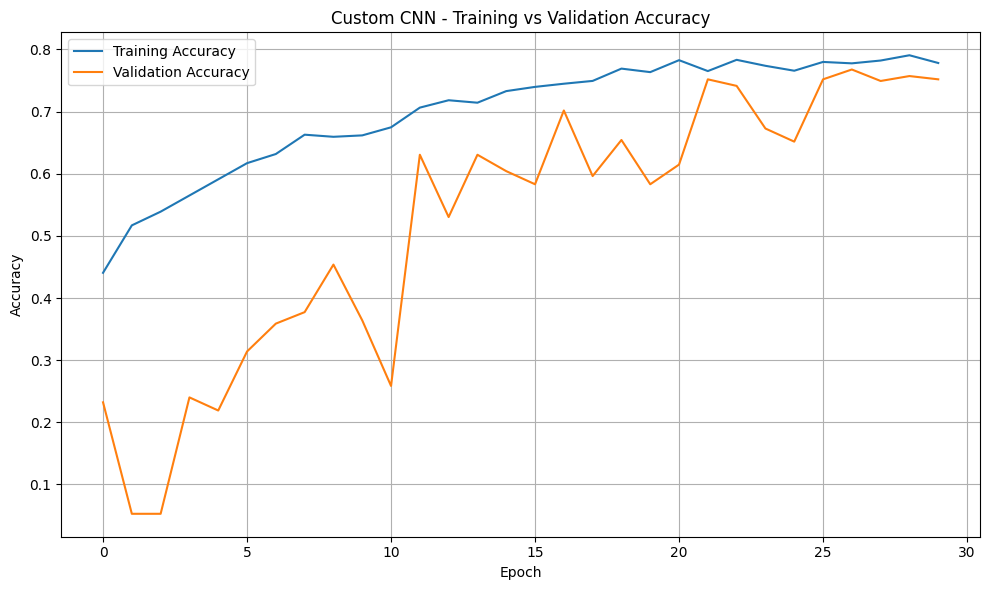

In [42]:
history_df = pd.DataFrame(cnn_history.history)

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Custom CNN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "cnn_accuracy.png",
    dpi=300
)

plt.show()

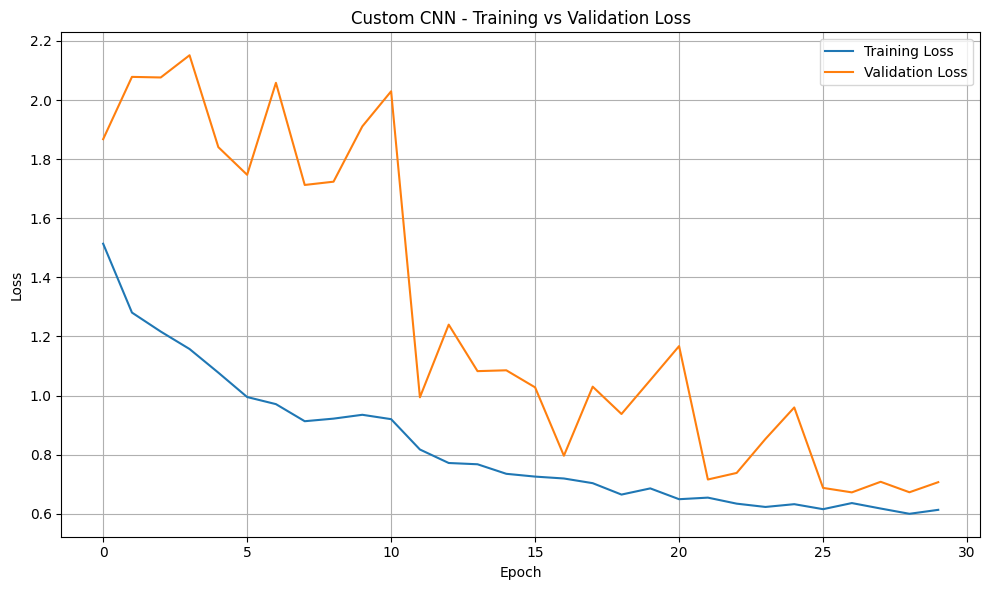

In [43]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["loss"],
    label="Training Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.title("Custom CNN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "cnn_loss.png",
    dpi=300
)

plt.show()

In [44]:
# Generate predictions
y_prob = cnn_model.predict(test_ds)

# Predicted class labels
y_pred = np.argmax(y_prob, axis=1)

# Actual class labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

print("Predictions generated!")
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step
Predictions generated!
Actual labels: 379
Predicted labels: 379


In [45]:
cnn_accuracy = accuracy_score(y_true, y_pred)

cnn_precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("=" * 45)
print("CUSTOM CNN - TEST PERFORMANCE")
print("=" * 45)

print(f"Accuracy:  {cnn_accuracy:.4f}")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall:    {cnn_recall:.4f}")
print(f"F1 Score:  {cnn_f1:.4f}")

CUSTOM CNN - TEST PERFORMANCE
Accuracy:  0.7309
Precision: 0.7027
Recall:    0.7212
F1 Score:  0.6962


In [46]:
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
)

print(report)

with open(
    OUTPUT_DIR / "cnn_classification_report.txt",
    "w"
) as f:
    f.write(report)

              precision    recall  f1-score   support

   cardboard       0.85      0.97      0.91        60
       glass       0.82      0.53      0.64        76
       metal       0.68      0.52      0.59        61
       paper       0.77      0.87      0.81        89
     plastic       0.74      0.78      0.76        72
       trash       0.36      0.67      0.47        21

    accuracy                           0.73       379
   macro avg       0.70      0.72      0.70       379
weighted avg       0.75      0.73      0.73       379



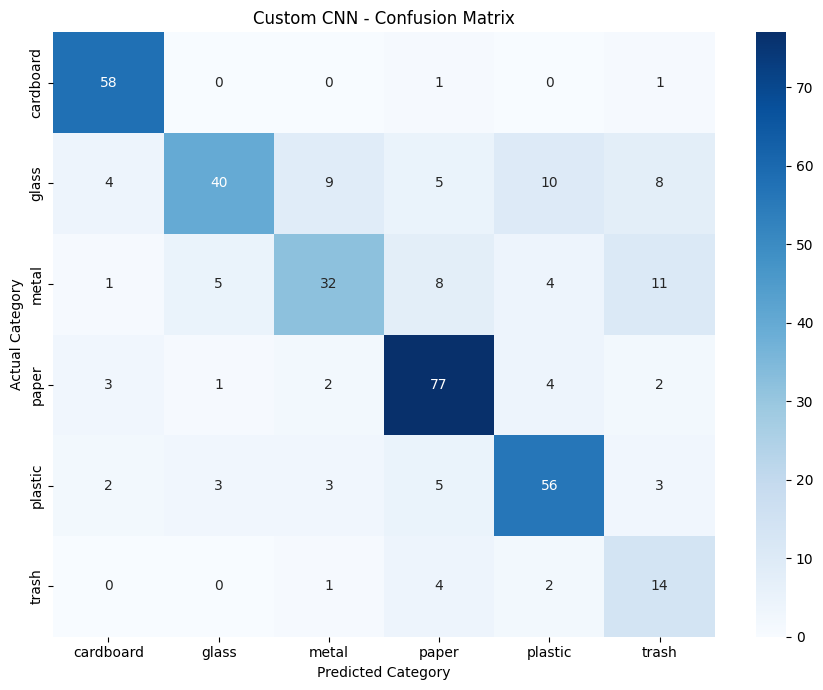

In [47]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "cnn_confusion_matrix.png",
    dpi=300
)

plt.show()

In [48]:
final_model_path = MODEL_DIR / "cnn_model.keras"

cnn_model.save(final_model_path)

print("CNN model saved successfully!")
print("Location:", final_model_path)

CNN model saved successfully!
Location: /content/drive/MyDrive/Waste_Classification/models/cnn_model.keras


In [49]:
cnn_results = {
    "model": "Custom CNN",
    "accuracy": float(cnn_accuracy),
    "precision_macro": float(cnn_precision),
    "recall_macro": float(cnn_recall),
    "f1_macro": float(cnn_f1),
    "epochs_trained": len(cnn_history.history["loss"])
}

with open(
    OUTPUT_DIR / "cnn_results.json",
    "w"
) as f:
    json.dump(cnn_results, f, indent=4)

print(json.dumps(cnn_results, indent=4))

{
    "model": "Custom CNN",
    "accuracy": 0.7308707124010554,
    "precision_macro": 0.7026558725250229,
    "recall_macro": 0.7211976006408441,
    "f1_macro": 0.6961801384718052,
    "epochs_trained": 30
}


In [50]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 3 REPORT")
print("=" * 55)

print("Model: Custom CNN")
print("Architecture: 4 Convolutional Blocks")
print("Input Size: 224 x 224 x 3")
print("Output Classes:", NUM_CLASSES)

print("\nTEST PERFORMANCE")
print("-" * 40)

print(f"Accuracy:  {cnn_accuracy * 100:.2f}%")
print(f"Precision: {cnn_precision * 100:.2f}%")
print(f"Recall:    {cnn_recall * 100:.2f}%")
print(f"F1 Score:  {cnn_f1 * 100:.2f}%")

print("\nTRAINING")
print("-" * 40)

print("Epochs completed:", len(cnn_history.history["loss"]))

print("\nSAVED MODEL")
print("-" * 40)

print("Model exists:", final_model_path.exists())

print("\nGENERATED FILES")
print("-" * 40)

for file in OUTPUT_DIR.iterdir():
    if file.is_file() and file.name.startswith("cnn_"):
        print("-", file.name)

print("\n" + "=" * 55)
print("STAGE 3 COMPLETED!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 3 REPORT
Model: Custom CNN
Architecture: 4 Convolutional Blocks
Input Size: 224 x 224 x 3
Output Classes: 6

TEST PERFORMANCE
----------------------------------------
Accuracy:  73.09%
Precision: 70.27%
Recall:    72.12%
F1 Score:  69.62%

TRAINING
----------------------------------------
Epochs completed: 30

SAVED MODEL
----------------------------------------
Model exists: True

GENERATED FILES
----------------------------------------
- cnn_training_history.csv
- cnn_accuracy.png
- cnn_loss.png
- cnn_classification_report.txt
- cnn_confusion_matrix.png
- cnn_results.json

STAGE 3 COMPLETED!


# Stage 4

In [51]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

IMG_SIZE = (224, 224)
NUM_CLASSES = 6
EPOCHS_HEAD = 15
EPOCHS_FINE = 15

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

print("MobileNetV2 configuration ready!")

MobileNetV2 configuration ready!


In [52]:
def mobilenet_preprocessing(image, label):

    image = image * 255.0

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, label


mobilenet_train_ds = train_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_val_ds = val_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_test_ds = test_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("MobileNetV2 preprocessing completed!")

MobileNetV2 preprocessing completed!


In [53]:
images, labels = next(iter(mobilenet_train_ds))

print("Image shape:", images.shape)
print("Minimum pixel:", tf.reduce_min(images).numpy())
print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Minimum pixel: -1.0
Maximum pixel: 1.0513234


In [54]:
base_model = tf.keras.applications.MobileNetV2(

    input_shape=(224, 224, 3),

    include_top=False,

    weights="imagenet"

)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 pretrained model loaded!")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 pretrained model loaded!
Total layers: 154


In [55]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

# Extract pretrained image features
x = base_model(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

mobilenet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="MobileNetV2_Waste_Classifier"
)

print("MobileNetV2 classification head created!")

mobilenet_model.summary()

MobileNetV2 classification head created!


Model: "MobileNetV2_Waste_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [56]:
mobilenet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [57]:
mobilenet_checkpoint = MODEL_DIR / "mobilenetv2_best.keras"

mobilenet_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(mobilenet_checkpoint),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "mobilenetv2_head_history.csv")
    )
]

print("Callbacks configured!")

Callbacks configured!


In [58]:
start_time = time.time()

mobilenet_history_head = mobilenet_model.fit(

    mobilenet_train_ds,

    validation_data=mobilenet_val_ds,

    epochs=EPOCHS_HEAD,

    class_weight=CLASS_WEIGHTS,

    callbacks=mobilenet_callbacks,

    verbose=1

)

head_training_time = time.time() - start_time

print("\nFeature extraction completed!")

print(
    "Training time:",
    round(head_training_time / 60, 2),
    "minutes"
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4262 - loss: 1.5450   
Epoch 1: val_loss improved from None to 0.72540, saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.5481 - loss: 1.2041 - val_accuracy: 0.7414 - val_loss: 0.7254 - learning_rate: 0.0010
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.7285 - loss: 0.7253
Epoch 2: val_loss improved from 0.72540 to 0.64429, saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 470ms/step - accuracy: 0.7296 - loss: 0.7285 - val_accuracy: 0.7810 - val_loss: 0.6443 - learning_rate: 0.0010
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/

In [59]:
# Unfreeze the pretrained base
base_model.trainable = True

# Freeze all layers initially
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze selected deeper layers
for layer in base_model.layers[-30:]:

    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print("Total MobileNetV2 layers:", len(base_model.layers))

print(
    "Trainable layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

Total MobileNetV2 layers: 154
Trainable layers: 19


In [60]:
mobilenet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [61]:
fine_tune_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_finetuned_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "mobilenetv2_finetune_history.csv")
    )
]

In [62]:
fine_tune_start = time.time()

mobilenet_history_fine = mobilenet_model.fit(

    mobilenet_train_ds,

    validation_data=mobilenet_val_ds,

    epochs=EPOCHS_FINE,

    class_weight=CLASS_WEIGHTS,

    callbacks=fine_tune_callbacks,

    verbose=1

)

fine_tune_time = time.time() - fine_tune_start

print("\nFine-tuning completed!")

print(
    "Fine-tuning time:",
    round(fine_tune_time / 60, 2),
    "minutes"
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.8847 - loss: 0.3242
Epoch 1: val_loss improved from None to 0.56474, saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_finetuned_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 59s 713ms/step - accuracy: 0.8818 - loss: 0.3261 - val_accuracy: 0.8206 - val_loss: 0.5647 - learning_rate: 1.0000e-05
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.8868 - loss: 0.3113
Epoch 2: val_loss improved from 0.56474 to 0.53476, saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_finetuned_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 513ms/step - accuracy: 0.8846 - loss: 0.3104 - val_accuracy: 0.8259 - val_loss: 0.5348 - learning_rate: 1.0000e-

In [63]:
head_history = mobilenet_history_head.history
fine_history = mobilenet_history_fine.history

mobilenet_history = {}

for key in head_history:

    mobilenet_history[key] = (
        head_history[key] + fine_history[key]
    )

mobilenet_history_df = pd.DataFrame(
    mobilenet_history
)

mobilenet_history_df.to_csv(
    OUTPUT_DIR / "mobilenetv2_training_history.csv",
    index=False
)

print("Training histories combined!")
print("Total epochs:", len(mobilenet_history_df))

Training histories combined!
Total epochs: 22


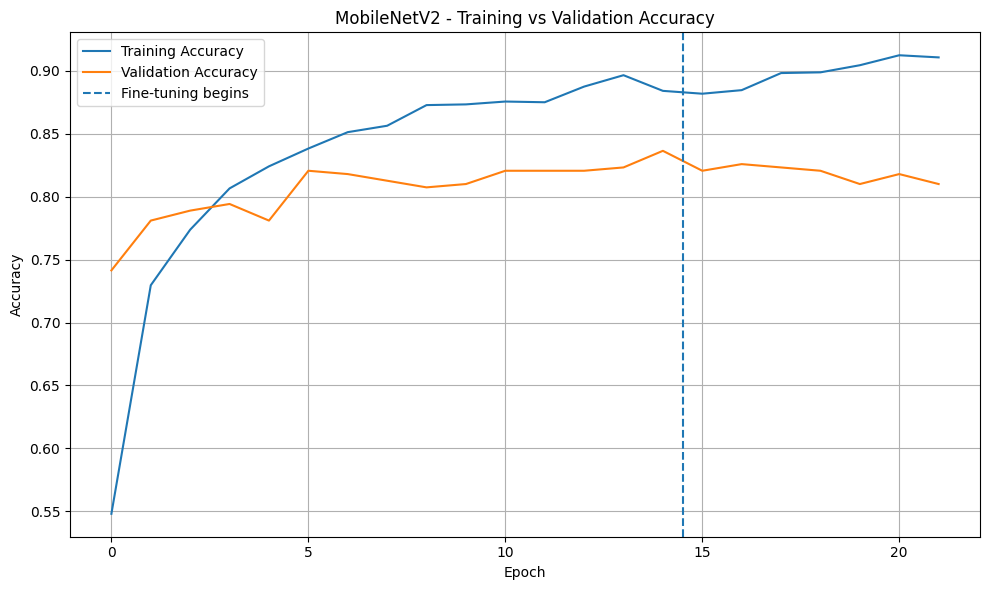

In [64]:
plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    mobilenet_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=len(head_history["accuracy"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("MobileNetV2 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "mobilenetv2_accuracy.png",
    dpi=300
)

plt.show()

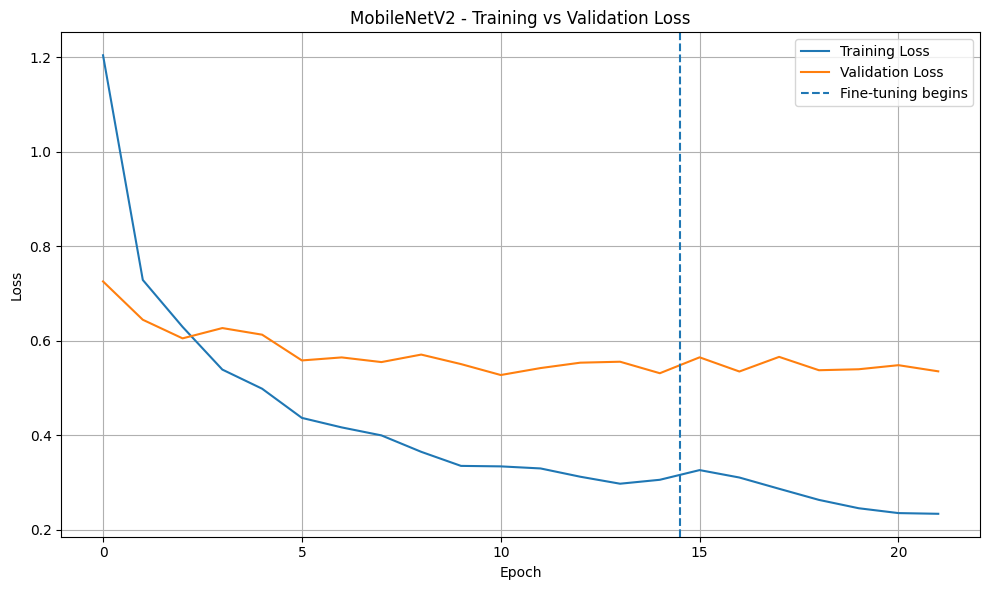

In [65]:
plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_history["loss"],
    label="Training Loss"
)

plt.plot(
    mobilenet_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=len(head_history["loss"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("MobileNetV2 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "mobilenetv2_loss.png",
    dpi=300
)

plt.show()

In [66]:
mobilenet_prob = mobilenet_model.predict(
    mobilenet_test_ds,
    verbose=1
)

mobilenet_pred = np.argmax(
    mobilenet_prob,
    axis=1
)

mobilenet_true = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_test_ds
])

print("Predictions generated!")
print("Actual samples:", len(mobilenet_true))
print("Predicted samples:", len(mobilenet_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 343ms/step
Predictions generated!
Actual samples: 379
Predicted samples: 379


In [67]:
mobilenet_accuracy = accuracy_score(
    mobilenet_true,
    mobilenet_pred
)

mobilenet_precision = precision_score(
    mobilenet_true,
    mobilenet_pred,
    average="macro",
    zero_division=0
)

mobilenet_recall = recall_score(
    mobilenet_true,
    mobilenet_pred,
    average="macro",
    zero_division=0
)

mobilenet_f1 = f1_score(
    mobilenet_true,
    mobilenet_pred,
    average="macro",
    zero_division=0
)

print("=" * 45)
print("MOBILENETV2 - TEST PERFORMANCE")
print("=" * 45)

print(f"Accuracy:  {mobilenet_accuracy * 100:.2f}%")
print(f"Precision: {mobilenet_precision * 100:.2f}%")
print(f"Recall:    {mobilenet_recall * 100:.2f}%")
print(f"F1 Score:  {mobilenet_f1 * 100:.2f}%")

MOBILENETV2 - TEST PERFORMANCE
Accuracy:  87.07%
Precision: 87.29%
Recall:    85.67%
F1 Score:  86.01%


In [68]:
mobilenet_report = classification_report(
    mobilenet_true,
    mobilenet_pred,
    target_names=CLASSES,
    zero_division=0
)

print(mobilenet_report)

with open(
    OUTPUT_DIR / "mobilenetv2_classification_report.txt",
    "w"
) as f:

    f.write(mobilenet_report)

              precision    recall  f1-score   support

   cardboard       0.88      0.95      0.91        60
       glass       0.94      0.78      0.85        76
       metal       0.76      0.95      0.85        61
       paper       0.93      0.89      0.91        89
     plastic       0.85      0.86      0.86        72
       trash       0.88      0.71      0.79        21

    accuracy                           0.87       379
   macro avg       0.87      0.86      0.86       379
weighted avg       0.88      0.87      0.87       379



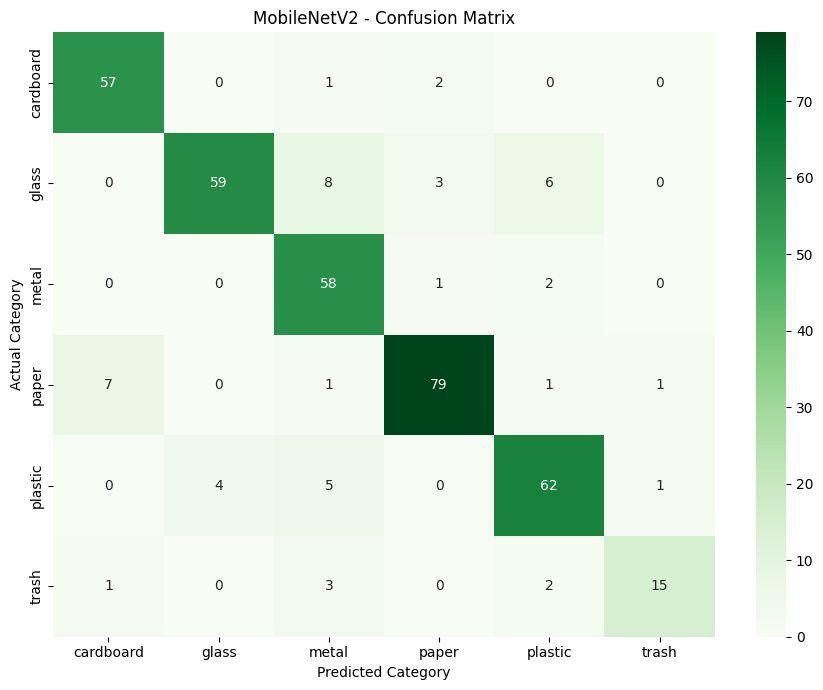

In [69]:
mobilenet_cm = confusion_matrix(
    mobilenet_true,
    mobilenet_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "mobilenetv2_confusion_matrix.png",
    dpi=300
)

plt.show()

In [70]:
mobilenet_final_path = MODEL_DIR / "mobilenetv2_model.keras"

mobilenet_model.save(
    mobilenet_final_path
)

print("MobileNetV2 model saved!")
print("Location:", mobilenet_final_path)

MobileNetV2 model saved!
Location: /content/drive/MyDrive/Waste_Classification/models/mobilenetv2_model.keras


In [71]:
mobilenet_results = {

    "model": "MobileNetV2",

    "accuracy": float(mobilenet_accuracy),

    "precision_macro": float(mobilenet_precision),

    "recall_macro": float(mobilenet_recall),

    "f1_macro": float(mobilenet_f1),

    "head_epochs": len(mobilenet_history_head.history["loss"]),

    "fine_tune_epochs": len(mobilenet_history_fine.history["loss"]),

    "head_training_time_seconds": float(head_training_time),

    "fine_tune_time_seconds": float(fine_tune_time),

    "total_training_time_seconds": float(
        head_training_time + fine_tune_time
    )
}

with open(
    OUTPUT_DIR / "mobilenetv2_results.json",
    "w"
) as f:

    json.dump(
        mobilenet_results,
        f,
        indent=4
    )

print(json.dumps(mobilenet_results, indent=4))

{
    "model": "MobileNetV2",
    "accuracy": 0.8707124010554089,
    "precision_macro": 0.8729447804238933,
    "recall_macro": 0.8566954560733099,
    "f1_macro": 0.8600547111319384,
    "head_epochs": 15,
    "fine_tune_epochs": 7,
    "head_training_time_seconds": 542.5986161231995,
    "fine_tune_time_seconds": 235.7672300338745,
    "total_training_time_seconds": 778.365846157074
}


In [72]:
comparison_df = pd.DataFrame([

    {
        "Model": "Custom CNN",
        "Accuracy": cnn_accuracy * 100,
        "Precision": cnn_precision * 100,
        "Recall": cnn_recall * 100,
        "F1 Score": cnn_f1 * 100
    },

    {
        "Model": "MobileNetV2",
        "Accuracy": mobilenet_accuracy * 100,
        "Precision": mobilenet_precision * 100,
        "Recall": mobilenet_recall * 100,
        "F1 Score": mobilenet_f1 * 100
    }

])

print(comparison_df.round(2))

comparison_df.to_csv(
    OUTPUT_DIR / "cnn_mobilenet_comparison.csv",
    index=False
)

         Model  Accuracy  Precision  Recall  F1 Score
0   Custom CNN     73.09      70.27   72.12     69.62
1  MobileNetV2     87.07      87.29   85.67     86.01


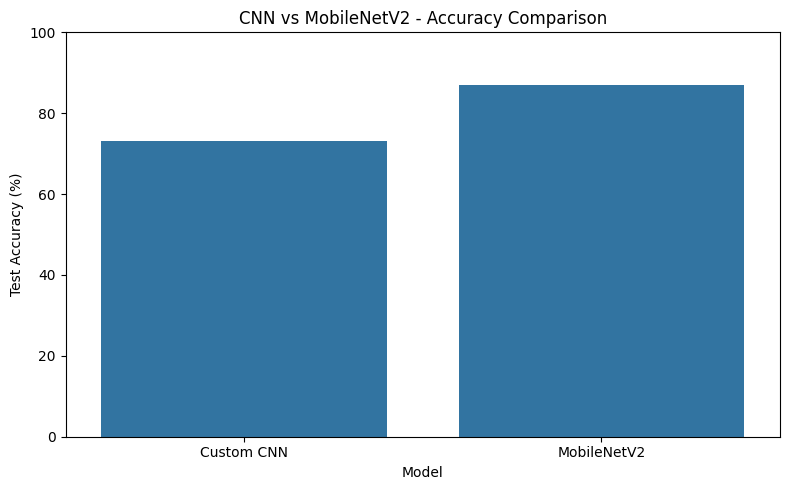

In [73]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.title("CNN vs MobileNetV2 - Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "cnn_mobilenet_comparison.png",
    dpi=300
)

plt.show()

In [74]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 4 REPORT")
print("=" * 55)

print("\nMODEL: MobileNetV2")
print("Architecture: ImageNet pretrained")
print("Training: Feature extraction + fine-tuning")
print("Input size: 224 x 224 x 3")
print("Output classes:", NUM_CLASSES)

print("\nTEST PERFORMANCE")
print("-" * 40)

print(f"Accuracy:  {mobilenet_accuracy * 100:.2f}%")
print(f"Precision: {mobilenet_precision * 100:.2f}%")
print(f"Recall:    {mobilenet_recall * 100:.2f}%")
print(f"F1 Score:  {mobilenet_f1 * 100:.2f}%")

print("\nMODEL COMPARISON")
print("-" * 40)

print(comparison_df.round(2).to_string(index=False))

print("\nSAVED MODEL")
print("-" * 40)

print("Model exists:", mobilenet_final_path.exists())

print("\nSTAGE 4 COMPLETED!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 4 REPORT

MODEL: MobileNetV2
Architecture: ImageNet pretrained
Training: Feature extraction + fine-tuning
Input size: 224 x 224 x 3
Output classes: 6

TEST PERFORMANCE
----------------------------------------
Accuracy:  87.07%
Precision: 87.29%
Recall:    85.67%
F1 Score:  86.01%

MODEL COMPARISON
----------------------------------------
      Model  Accuracy  Precision  Recall  F1 Score
 Custom CNN     73.09      70.27   72.12     69.62
MobileNetV2     87.07      87.29   85.67     86.01

SAVED MODEL
----------------------------------------
Model exists: True

STAGE 4 COMPLETED!


# Stage 5

In [75]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, Model

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

print("TensorFlow:", tf.__version__)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

IMG_SIZE = (224, 224)
NUM_CLASSES = 6

BATCH_SIZE_VGG = 16

print("VGG16 configuration ready!")

TensorFlow: 2.21.0
VGG16 configuration ready!


In [76]:
def vgg16_preprocessing(image, label):

    image = image * 255.0

    image = tf.keras.applications.vgg16.preprocess_input(
        image
    )

    return image, label


# Reduce batch size for VGG16
vgg_train_ds = (
    train_ds
    .unbatch()
    .map(
        vgg16_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG)
    .prefetch(tf.data.AUTOTUNE)
)

vgg_val_ds = (
    val_ds
    .unbatch()
    .map(
        vgg16_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG)
    .prefetch(tf.data.AUTOTUNE)
)

vgg_test_ds = (
    test_ds
    .unbatch()
    .map(
        vgg16_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG)
    .prefetch(tf.data.AUTOTUNE)
)

print("VGG16 preprocessing completed!")

VGG16 preprocessing completed!


In [77]:
images, labels = next(iter(vgg_train_ds))

print("Image shape:", images.shape)
print("Minimum pixel:", tf.reduce_min(images).numpy())
print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (16, 224, 224, 3)
Minimum pixel: -123.68
Maximum pixel: 156.83365


In [78]:
base_vgg16 = tf.keras.applications.VGG16(

    input_shape=(224, 224, 3),

    include_top=False,

    weights="imagenet"

)

# Freeze pretrained layers initially
base_vgg16.trainable = False

print("VGG16 pretrained model loaded!")
print("Total layers:", len(base_vgg16.layers))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16 pretrained model loaded!
Total layers: 19


In [79]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

x = base_vgg16(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

vgg16_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="VGG16_Waste_Classifier"
)

print("VGG16 classifier created!")

vgg16_model.summary()

VGG16 classifier created!


Model: "VGG16_Waste_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,558 (56.64 MB)

 Trainable params: 132,870 (519.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [80]:
vgg16_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("VGG16 compiled successfully!")

VGG16 compiled successfully!


In [81]:
vgg16_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "vgg16_head_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "vgg16_head_history.csv")
    )
]

print("VGG16 callbacks configured!")

VGG16 callbacks configured!


In [82]:
vgg16_start = time.time()

vgg16_history_head = vgg16_model.fit(

    vgg_train_ds,

    validation_data=vgg_val_ds,

    epochs=15,

    class_weight=CLASS_WEIGHTS,

    callbacks=vgg16_callbacks,

    verbose=1

)

vgg16_head_time = time.time() - vgg16_start

print("\nVGG16 feature extraction completed!")

print(
    "Training time:",
    round(vgg16_head_time / 60, 2),
    "minutes"
)

Epoch 1/15
    111/Unknown 62s 349ms/step - accuracy: 0.2350 - loss: 4.0831

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 1.33555, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_head_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 76s 479ms/step - accuracy: 0.3105 - loss: 3.2215 - val_accuracy: 0.5488 - val_loss: 1.3356 - learning_rate: 1.0000e-04
Epoch 2/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.4781 - loss: 1.8561
Epoch 2: val_loss improved from 1.33555 to 1.06202, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_head_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_head_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 70s 632ms/step - accuracy: 0.4983 - loss: 1.7228 - val_accuracy: 0.6438 - val_loss: 1.0620 - learning_rate: 1.0000e-04
Epoch 3/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.5647 - loss: 1.3591
Epoch 3: val_loss improved from 

In [83]:
# Unfreeze VGG16 base
base_vgg16.trainable = True

# Freeze all layers first
for layer in base_vgg16.layers:
    layer.trainable = False

# Unfreeze block 5
for layer in base_vgg16.layers:

    if layer.name.startswith("block5_"):
        layer.trainable = True

print("VGG16 layers:", len(base_vgg16.layers))

print(
    "Trainable base layers:",
    sum(
        layer.trainable
        for layer in base_vgg16.layers
    )
)

VGG16 layers: 19
Trainable base layers: 4


In [84]:
vgg16_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("VGG16 recompiled for fine-tuning!")

VGG16 recompiled for fine-tuning!


In [85]:
vgg16_fine_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "vgg16_finetuned_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "vgg16_finetune_history.csv")
    )
]

print("Fine-tuning callbacks configured!")

Fine-tuning callbacks configured!


In [86]:
vgg16_fine_start = time.time()

vgg16_history_fine = vgg16_model.fit(

    vgg_train_ds,

    validation_data=vgg_val_ds,

    epochs=10,

    class_weight=CLASS_WEIGHTS,

    callbacks=vgg16_fine_callbacks,

    verbose=1

)

vgg16_fine_time = time.time() - vgg16_fine_start

print("\nVGG16 fine-tuning completed!")

print(
    "Fine-tuning time:",
    round(vgg16_fine_time / 60, 2),
    "minutes"
)

Epoch 1/10
    111/Unknown 43s 298ms/step - accuracy: 0.8207 - loss: 0.5042
Epoch 1: val_loss improved from None to 0.58108, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_finetuned_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 47s 334ms/step - accuracy: 0.8275 - loss: 0.4931 - val_accuracy: 0.8127 - val_loss: 0.5811 - learning_rate: 1.0000e-05
Epoch 2/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.8584 - loss: 0.4054
Epoch 2: val_loss improved from 0.58108 to 0.56835, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg16_finetuned_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 36s 322ms/step - accuracy: 0.8473 - loss: 0.4020 - val_accuracy: 0.8232 - val_loss: 0.5684 - learning_rate: 1.0000e-05
Epoch 3/10
111/111 ━━━━━━

In [87]:
head_history = vgg16_history_head.history
fine_history = vgg16_history_fine.history

vgg16_history = {}

for key in head_history:

    vgg16_history[key] = (
        head_history[key] + fine_history[key]
    )

vgg16_history_df = pd.DataFrame(
    vgg16_history
)

vgg16_history_df.to_csv(
    OUTPUT_DIR / "vgg16_training_history.csv",
    index=False
)

print("VGG16 training histories combined!")
print("Total epochs:", len(vgg16_history_df))

VGG16 training histories combined!
Total epochs: 25


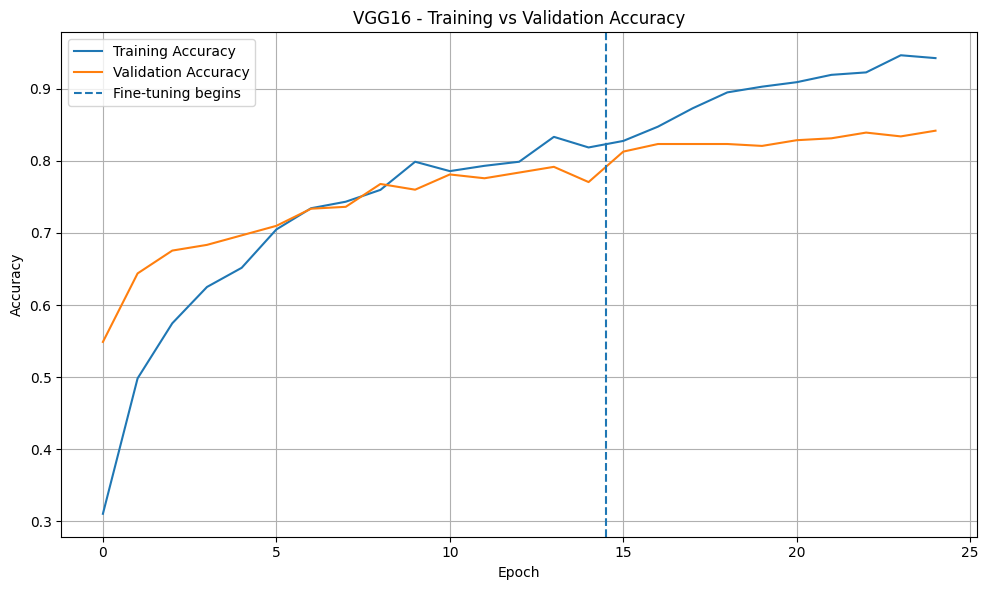

In [88]:
plt.figure(figsize=(10, 6))

plt.plot(
    vgg16_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    vgg16_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=len(head_history["accuracy"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("VGG16 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg16_accuracy.png",
    dpi=300
)

plt.show()

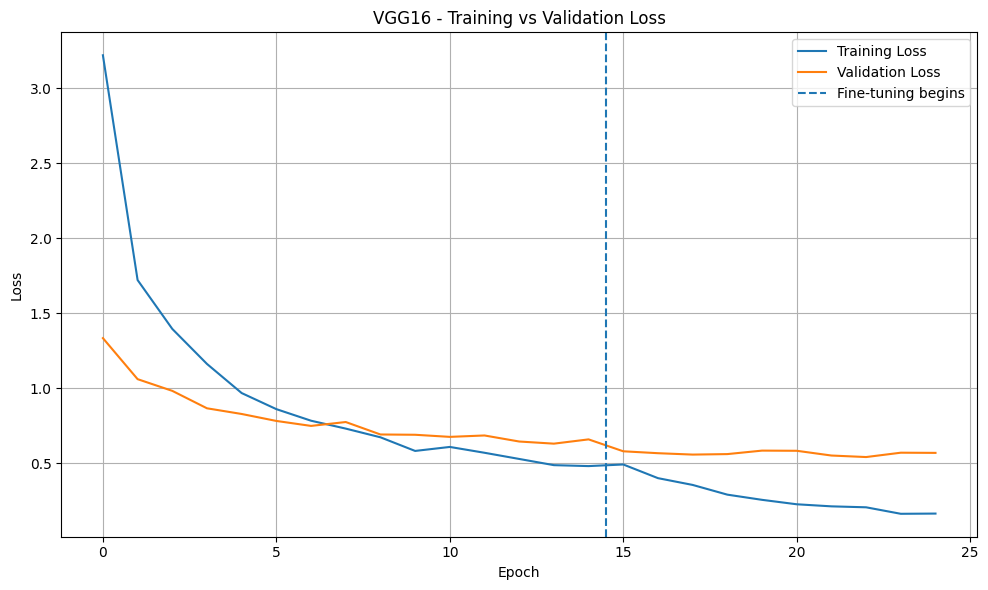

In [89]:
plt.figure(figsize=(10, 6))

plt.plot(
    vgg16_history["loss"],
    label="Training Loss"
)

plt.plot(
    vgg16_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=len(head_history["loss"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("VGG16 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg16_loss.png",
    dpi=300
)

plt.show()

In [90]:
vgg16_prob = vgg16_model.predict(
    vgg_test_ds,
    verbose=1
)

vgg16_pred = np.argmax(
    vgg16_prob,
    axis=1
)

vgg16_true = np.concatenate([
    labels.numpy()
    for images, labels in vgg_test_ds
])

print("VGG16 predictions generated!")
print("Actual samples:", len(vgg16_true))
print("Predicted samples:", len(vgg16_pred))

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 112ms/step
VGG16 predictions generated!
Actual samples: 379
Predicted samples: 379


In [91]:
vgg16_accuracy = accuracy_score(
    vgg16_true,
    vgg16_pred
)

vgg16_precision = precision_score(
    vgg16_true,
    vgg16_pred,
    average="macro",
    zero_division=0
)

vgg16_recall = recall_score(
    vgg16_true,
    vgg16_pred,
    average="macro",
    zero_division=0
)

vgg16_f1 = f1_score(
    vgg16_true,
    vgg16_pred,
    average="macro",
    zero_division=0
)

print("=" * 45)
print("VGG16 - TEST PERFORMANCE")
print("=" * 45)

print(f"Accuracy:  {vgg16_accuracy * 100:.2f}%")
print(f"Precision: {vgg16_precision * 100:.2f}%")
print(f"Recall:    {vgg16_recall * 100:.2f}%")
print(f"F1 Score:  {vgg16_f1 * 100:.2f}%")

VGG16 - TEST PERFORMANCE
Accuracy:  88.65%
Precision: 87.58%
Recall:    88.14%
F1 Score:  87.69%


In [92]:
vgg16_report = classification_report(
    vgg16_true,
    vgg16_pred,
    target_names=CLASSES,
    zero_division=0
)

print(vgg16_report)

with open(
    OUTPUT_DIR / "vgg16_classification_report.txt",
    "w"
) as f:

    f.write(vgg16_report)

              precision    recall  f1-score   support

   cardboard       0.86      0.93      0.90        60
       glass       0.93      0.87      0.90        76
       metal       0.80      0.93      0.86        61
       paper       0.95      0.85      0.90        89
     plastic       0.90      0.89      0.90        72
       trash       0.81      0.81      0.81        21

    accuracy                           0.89       379
   macro avg       0.88      0.88      0.88       379
weighted avg       0.89      0.89      0.89       379



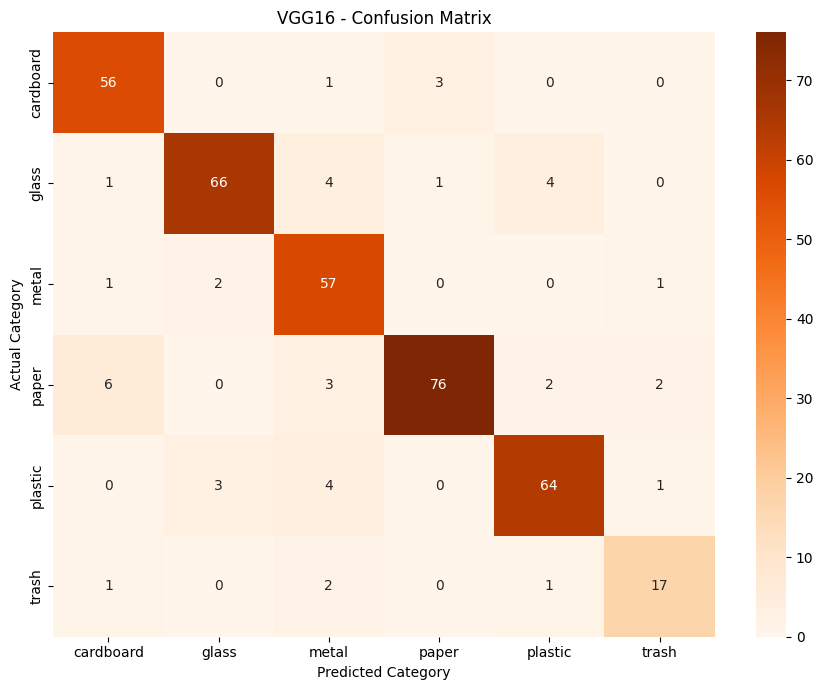

In [93]:
vgg16_cm = confusion_matrix(
    vgg16_true,
    vgg16_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    vgg16_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("VGG16 - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg16_confusion_matrix.png",
    dpi=300
)

plt.show()

In [94]:
vgg16_final_path = MODEL_DIR / "vgg16_model.keras"

vgg16_model.save(
    vgg16_final_path
)

print("VGG16 model saved successfully!")
print("Location:", vgg16_final_path)

VGG16 model saved successfully!
Location: /content/drive/MyDrive/Waste_Classification/models/vgg16_model.keras


In [95]:
vgg16_results = {

    "model": "VGG16",

    "accuracy": float(vgg16_accuracy),

    "precision_macro": float(vgg16_precision),

    "recall_macro": float(vgg16_recall),

    "f1_macro": float(vgg16_f1),

    "head_epochs": len(vgg16_history_head.history["loss"]),

    "fine_tune_epochs": len(vgg16_history_fine.history["loss"]),

    "head_training_time_seconds": float(vgg16_head_time),

    "fine_tune_time_seconds": float(vgg16_fine_time),

    "total_training_time_seconds": float(
        vgg16_head_time + vgg16_fine_time
    )
}

with open(
    OUTPUT_DIR / "vgg16_results.json",
    "w"
) as f:

    json.dump(
        vgg16_results,
        f,
        indent=4
    )

print(json.dumps(vgg16_results, indent=4))

{
    "model": "VGG16",
    "accuracy": 0.8865435356200527,
    "precision_macro": 0.8758108479939466,
    "recall_macro": 0.8814209830259117,
    "f1_macro": 0.8769387559937011,
    "head_epochs": 15,
    "fine_tune_epochs": 10,
    "head_training_time_seconds": 648.4801561832428,
    "fine_tune_time_seconds": 438.78087544441223,
    "total_training_time_seconds": 1087.261031627655
}


In [96]:
comparison_data = [

    {
        "Model": "Custom CNN",
        "Accuracy": cnn_accuracy * 100,
        "Precision": cnn_precision * 100,
        "Recall": cnn_recall * 100,
        "F1 Score": cnn_f1 * 100
    },

    {
        "Model": "MobileNetV2",
        "Accuracy": mobilenet_accuracy * 100,
        "Precision": mobilenet_precision * 100,
        "Recall": mobilenet_recall * 100,
        "F1 Score": mobilenet_f1 * 100
    },

    {
        "Model": "VGG16",
        "Accuracy": vgg16_accuracy * 100,
        "Precision": vgg16_precision * 100,
        "Recall": vgg16_recall * 100,
        "F1 Score": vgg16_f1 * 100
    }

]

comparison_df = pd.DataFrame(comparison_data)

print(comparison_df.round(2))

comparison_df.to_csv(
    OUTPUT_DIR / "three_model_comparison.csv",
    index=False
)

         Model  Accuracy  Precision  Recall  F1 Score
0   Custom CNN     73.09      70.27   72.12     69.62
1  MobileNetV2     87.07      87.29   85.67     86.01
2        VGG16     88.65      87.58   88.14     87.69


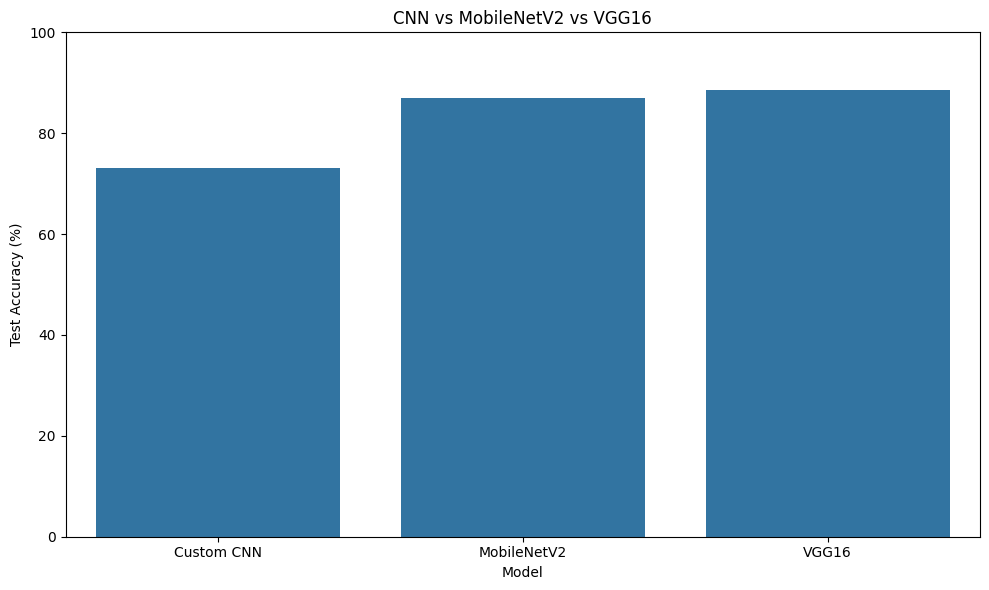

In [97]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.title("CNN vs MobileNetV2 vs VGG16")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "three_model_comparison.png",
    dpi=300
)

plt.show()

In [98]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 5 REPORT")
print("=" * 55)

print("Model: VGG16")
print("Architecture: ImageNet pretrained")
print("Training: Feature extraction + fine-tuning")
print("Input size: 224 x 224 x 3")
print("Output classes:", NUM_CLASSES)

print("\nTEST PERFORMANCE")
print("-" * 40)

print(f"Accuracy:  {vgg16_accuracy * 100:.2f}%")
print(f"Precision: {vgg16_precision * 100:.2f}%")
print(f"Recall:    {vgg16_recall * 100:.2f}%")
print(f"F1 Score:  {vgg16_f1 * 100:.2f}%")

print("\nMODEL COMPARISON")
print("-" * 40)

print(comparison_df.round(2).to_string(index=False))

print("\nSAVED MODEL")
print("-" * 40)

print("Model exists:", vgg16_final_path.exists())

print("\nSTAGE 5 COMPLETED!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 5 REPORT
Model: VGG16
Architecture: ImageNet pretrained
Training: Feature extraction + fine-tuning
Input size: 224 x 224 x 3
Output classes: 6

TEST PERFORMANCE
----------------------------------------
Accuracy:  88.65%
Precision: 87.58%
Recall:    88.14%
F1 Score:  87.69%

MODEL COMPARISON
----------------------------------------
      Model  Accuracy  Precision  Recall  F1 Score
 Custom CNN     73.09      70.27   72.12     69.62
MobileNetV2     87.07      87.29   85.67     86.01
      VGG16     88.65      87.58   88.14     87.69

SAVED MODEL
----------------------------------------
Model exists: True

STAGE 5 COMPLETED!


# Stage 6

In [101]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, Model

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

NUM_CLASSES = 6
BATCH_SIZE_VGG19 = 16

print("VGG19 configuration ready!")
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

VGG19 configuration ready!
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [102]:
def vgg19_preprocessing(image, label):

    image = image * 255.0

    image = tf.keras.applications.vgg19.preprocess_input(
        image
    )

    return image, label


vgg19_train_ds = (
    train_ds
    .unbatch()
    .map(
        vgg19_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG19)
    .prefetch(tf.data.AUTOTUNE)
)

vgg19_val_ds = (
    val_ds
    .unbatch()
    .map(
        vgg19_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG19)
    .prefetch(tf.data.AUTOTUNE)
)

vgg19_test_ds = (
    test_ds
    .unbatch()
    .map(
        vgg19_preprocessing,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE_VGG19)
    .prefetch(tf.data.AUTOTUNE)
)

print("VGG19 preprocessing completed!")

VGG19 preprocessing completed!


In [103]:
images, labels = next(iter(vgg19_train_ds))

print("Image shape:", images.shape)
print("Minimum pixel:", tf.reduce_min(images).numpy())
print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (16, 224, 224, 3)
Minimum pixel: -123.68
Maximum pixel: 157.86578


In [104]:
base_vgg19 = tf.keras.applications.VGG19(

    input_shape=(224, 224, 3),

    include_top=False,

    weights="imagenet"

)

base_vgg19.trainable = False

print("VGG19 pretrained model loaded!")
print("Total layers:", len(base_vgg19.layers))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
VGG19 pretrained model loaded!
Total layers: 22


In [105]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

x = base_vgg19(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

vgg19_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="VGG19_Waste_Classifier"
)

print("VGG19 classifier created!")

vgg19_model.summary()

VGG19 classifier created!


Model: "VGG19_Waste_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,157,254 (76.89 MB)

 Trainable params: 132,870 (519.02 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [106]:
vgg19_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("VGG19 compiled successfully!")

VGG19 compiled successfully!


In [107]:
vgg19_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "vgg19_head_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "vgg19_head_history.csv")
    )
]

print("VGG19 callbacks configured!")

VGG19 callbacks configured!


In [108]:
vgg19_start = time.time()

vgg19_history_head = vgg19_model.fit(

    vgg19_train_ds,

    validation_data=vgg19_val_ds,

    epochs=15,

    class_weight=CLASS_WEIGHTS,

    callbacks=vgg19_callbacks,

    verbose=1

)

vgg19_head_time = time.time() - vgg19_start

print("\nVGG19 feature extraction completed!")

print(
    "Training time:",
    round(vgg19_head_time / 60, 2),
    "minutes"
)

Epoch 1/15
    111/Unknown 43s 350ms/step - accuracy: 0.2639 - loss: 3.5213

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 1.37897, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_head_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 48s 389ms/step - accuracy: 0.3145 - loss: 3.0316 - val_accuracy: 0.5198 - val_loss: 1.3790 - learning_rate: 1.0000e-04
Epoch 2/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.4484 - loss: 1.9434
Epoch 2: val_loss improved from 1.37897 to 1.14914, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_head_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_head_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 39s 353ms/step - accuracy: 0.4689 - loss: 1.8710 - val_accuracy: 0.5963 - val_loss: 1.1491 - learning_rate: 1.0000e-04
Epoch 3/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.5396 - loss: 1.5019
Epoch 3: val_loss improved from 

In [109]:
base_vgg19.trainable = True

# Freeze all layers first
for layer in base_vgg19.layers:
    layer.trainable = False

# Unfreeze block 5
for layer in base_vgg19.layers:

    if layer.name.startswith("block5_"):
        layer.trainable = True

print("Total VGG19 layers:", len(base_vgg19.layers))

print(
    "Trainable base layers:",
    sum(
        layer.trainable
        for layer in base_vgg19.layers
    )
)

Total VGG19 layers: 22
Trainable base layers: 5


In [110]:
vgg19_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("VGG19 recompiled for fine-tuning!")

VGG19 recompiled for fine-tuning!


In [111]:
vgg19_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("VGG19 recompiled for fine-tuning!")

VGG19 recompiled for fine-tuning!


In [112]:
vgg19_fine_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "vgg19_finetuned_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        str(OUTPUT_DIR / "vgg19_finetune_history.csv")
    )
]

print("Fine-tuning callbacks configured!")

Fine-tuning callbacks configured!


In [113]:
vgg19_fine_start = time.time()

vgg19_history_fine = vgg19_model.fit(

    vgg19_train_ds,

    validation_data=vgg19_val_ds,

    epochs=10,

    class_weight=CLASS_WEIGHTS,

    callbacks=vgg19_fine_callbacks,

    verbose=1

)

vgg19_fine_time = time.time() - vgg19_fine_start

print("\nVGG19 fine-tuning completed!")

print(
    "Fine-tuning time:",
    round(vgg19_fine_time / 60, 2),
    "minutes"
)

Epoch 1/10
    111/Unknown 43s 305ms/step - accuracy: 0.8242 - loss: 0.4911
Epoch 1: val_loss improved from None to 0.65399, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_finetuned_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 47s 347ms/step - accuracy: 0.8258 - loss: 0.4874 - val_accuracy: 0.7810 - val_loss: 0.6540 - learning_rate: 1.0000e-05
Epoch 2/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.8411 - loss: 0.4005
Epoch 2: val_loss improved from 0.65399 to 0.52944, saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Waste_Classification/models/vgg19_finetuned_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 39s 352ms/step - accuracy: 0.8479 - loss: 0.3995 - val_accuracy: 0.8206 - val_loss: 0.5294 - learning_rate: 1.0000e-05
Epoch 3/10
111/111 ━━━━━━

In [114]:
head_history = vgg19_history_head.history
fine_history = vgg19_history_fine.history

vgg19_history = {}

for key in head_history:

    vgg19_history[key] = (
        head_history[key] + fine_history[key]
    )

vgg19_history_df = pd.DataFrame(
    vgg19_history
)

vgg19_history_df.to_csv(
    OUTPUT_DIR / "vgg19_training_history.csv",
    index=False
)

print("VGG19 training histories combined!")
print("Total epochs:", len(vgg19_history_df))

VGG19 training histories combined!
Total epochs: 25


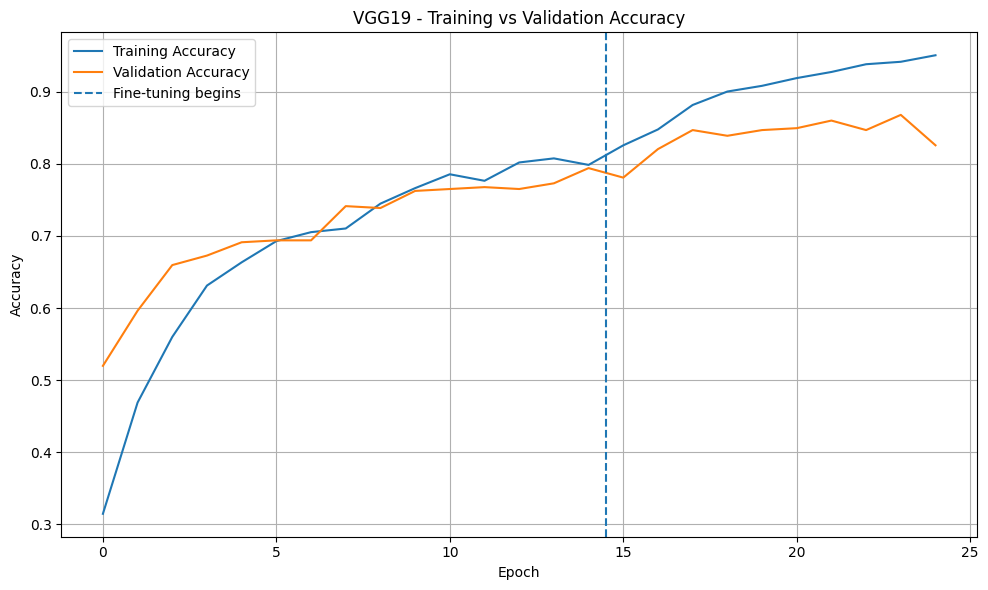

In [115]:
plt.figure(figsize=(10, 6))

plt.plot(
    vgg19_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    vgg19_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=len(head_history["accuracy"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("VGG19 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg19_accuracy.png",
    dpi=300
)

plt.show()

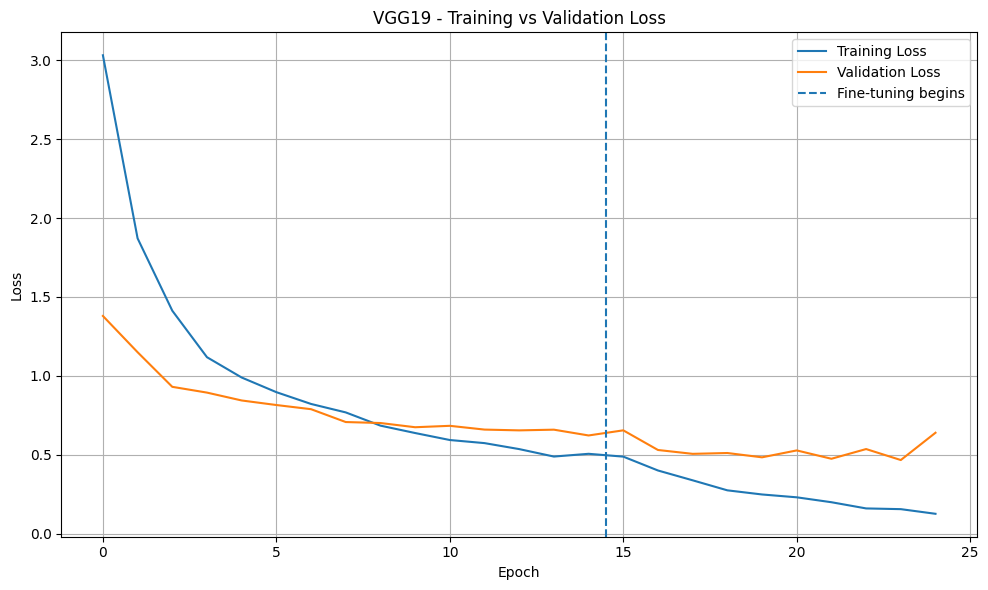

In [116]:
plt.figure(figsize=(10, 6))

plt.plot(
    vgg19_history["loss"],
    label="Training Loss"
)

plt.plot(
    vgg19_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=len(head_history["loss"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.title("VGG19 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg19_loss.png",
    dpi=300
)

plt.show()

In [117]:
vgg19_prob = vgg19_model.predict(
    vgg19_test_ds,
    verbose=1
)

vgg19_pred = np.argmax(
    vgg19_prob,
    axis=1
)

vgg19_true = np.concatenate([
    labels.numpy()
    for images, labels in vgg19_test_ds
])

print("VGG19 predictions generated!")
print("Actual samples:", len(vgg19_true))
print("Predicted samples:", len(vgg19_pred))

24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step
VGG19 predictions generated!
Actual samples: 379
Predicted samples: 379


In [118]:
vgg19_accuracy = accuracy_score(
    vgg19_true,
    vgg19_pred
)

vgg19_precision = precision_score(
    vgg19_true,
    vgg19_pred,
    average="macro",
    zero_division=0
)

vgg19_recall = recall_score(
    vgg19_true,
    vgg19_pred,
    average="macro",
    zero_division=0
)

vgg19_f1 = f1_score(
    vgg19_true,
    vgg19_pred,
    average="macro",
    zero_division=0
)

print("=" * 45)
print("VGG19 - TEST PERFORMANCE")
print("=" * 45)

print(f"Accuracy:  {vgg19_accuracy * 100:.2f}%")
print(f"Precision: {vgg19_precision * 100:.2f}%")
print(f"Recall:    {vgg19_recall * 100:.2f}%")
print(f"F1 Score:  {vgg19_f1 * 100:.2f}%")

VGG19 - TEST PERFORMANCE
Accuracy:  91.29%
Precision: 90.43%
Recall:    89.76%
F1 Score:  89.93%


In [119]:
vgg19_report = classification_report(
    vgg19_true,
    vgg19_pred,
    target_names=CLASSES,
    zero_division=0
)

print(vgg19_report)

with open(
    OUTPUT_DIR / "vgg19_classification_report.txt",
    "w"
) as f:

    f.write(vgg19_report)

              precision    recall  f1-score   support

   cardboard       0.93      0.95      0.94        60
       glass       0.91      0.91      0.91        76
       metal       0.85      0.98      0.91        61
       paper       0.94      0.92      0.93        89
     plastic       0.95      0.86      0.91        72
       trash       0.84      0.76      0.80        21

    accuracy                           0.91       379
   macro avg       0.90      0.90      0.90       379
weighted avg       0.92      0.91      0.91       379



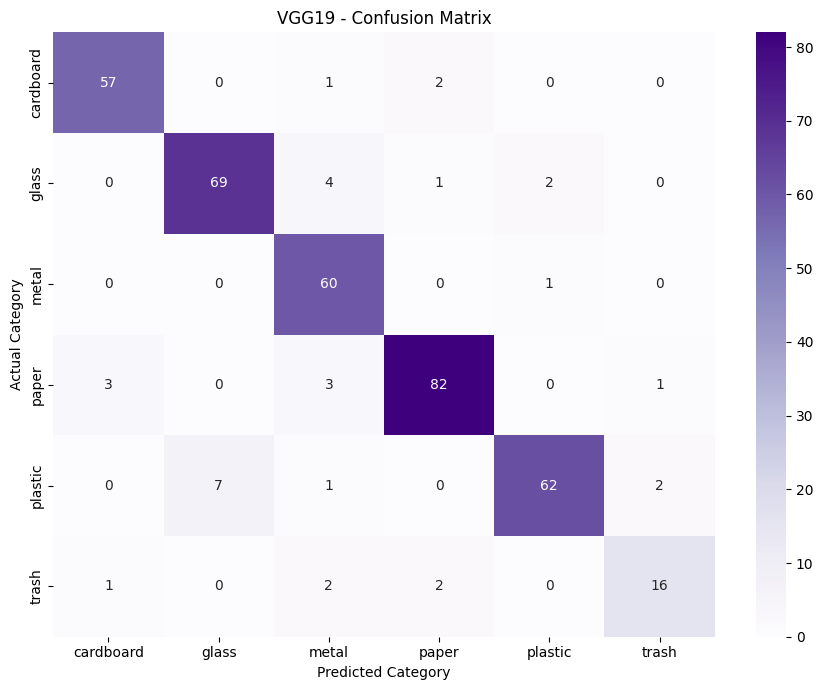

In [120]:
vgg19_cm = confusion_matrix(
    vgg19_true,
    vgg19_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    vgg19_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("VGG19 - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "vgg19_confusion_matrix.png",
    dpi=300
)

plt.show()

In [121]:
vgg19_final_path = MODEL_DIR / "vgg19_model.keras"

vgg19_model.save(
    vgg19_final_path
)

print("VGG19 model saved successfully!")
print("Location:", vgg19_final_path)

VGG19 model saved successfully!
Location: /content/drive/MyDrive/Waste_Classification/models/vgg19_model.keras


In [122]:
vgg19_results = {

    "model": "VGG19",

    "accuracy": float(vgg19_accuracy),

    "precision_macro": float(vgg19_precision),

    "recall_macro": float(vgg19_recall),

    "f1_macro": float(vgg19_f1),

    "head_epochs": len(vgg19_history_head.history["loss"]),

    "fine_tune_epochs": len(vgg19_history_fine.history["loss"]),

    "head_training_time_seconds": float(vgg19_head_time),

    "fine_tune_time_seconds": float(vgg19_fine_time),

    "total_training_time_seconds": float(
        vgg19_head_time + vgg19_fine_time
    )
}

with open(
    OUTPUT_DIR / "vgg19_results.json",
    "w"
) as f:

    json.dump(vgg19_results, f, indent=4)

print(json.dumps(vgg19_results, indent=4))

{
    "model": "VGG19",
    "accuracy": 0.9129287598944591,
    "precision_macro": 0.9043119235869576,
    "recall_macro": 0.8976442469736282,
    "f1_macro": 0.8993436795221449,
    "head_epochs": 15,
    "fine_tune_epochs": 10,
    "head_training_time_seconds": 618.6378755569458,
    "fine_tune_time_seconds": 495.6741704940796,
    "total_training_time_seconds": 1114.3120460510254
}


In [123]:
comparison_data = [

    {
        "Model": "Custom CNN",
        "Accuracy": cnn_accuracy * 100,
        "Precision": cnn_precision * 100,
        "Recall": cnn_recall * 100,
        "F1 Score": cnn_f1 * 100
    },

    {
        "Model": "MobileNetV2",
        "Accuracy": mobilenet_accuracy * 100,
        "Precision": mobilenet_precision * 100,
        "Recall": mobilenet_recall * 100,
        "F1 Score": mobilenet_f1 * 100
    },

    {
        "Model": "VGG16",
        "Accuracy": vgg16_accuracy * 100,
        "Precision": vgg16_precision * 100,
        "Recall": vgg16_recall * 100,
        "F1 Score": vgg16_f1 * 100
    },

    {
        "Model": "VGG19",
        "Accuracy": vgg19_accuracy * 100,
        "Precision": vgg19_precision * 100,
        "Recall": vgg19_recall * 100,
        "F1 Score": vgg19_f1 * 100
    }

]

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    range(1, len(comparison_df) + 1)
)

print(comparison_df.round(2).to_string(index=False))

comparison_df.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

 Rank       Model  Accuracy  Precision  Recall  F1 Score
    1       VGG19     91.29      90.43   89.76     89.93
    2       VGG16     88.65      87.58   88.14     87.69
    3 MobileNetV2     87.07      87.29   85.67     86.01
    4  Custom CNN     73.09      70.27   72.12     69.62


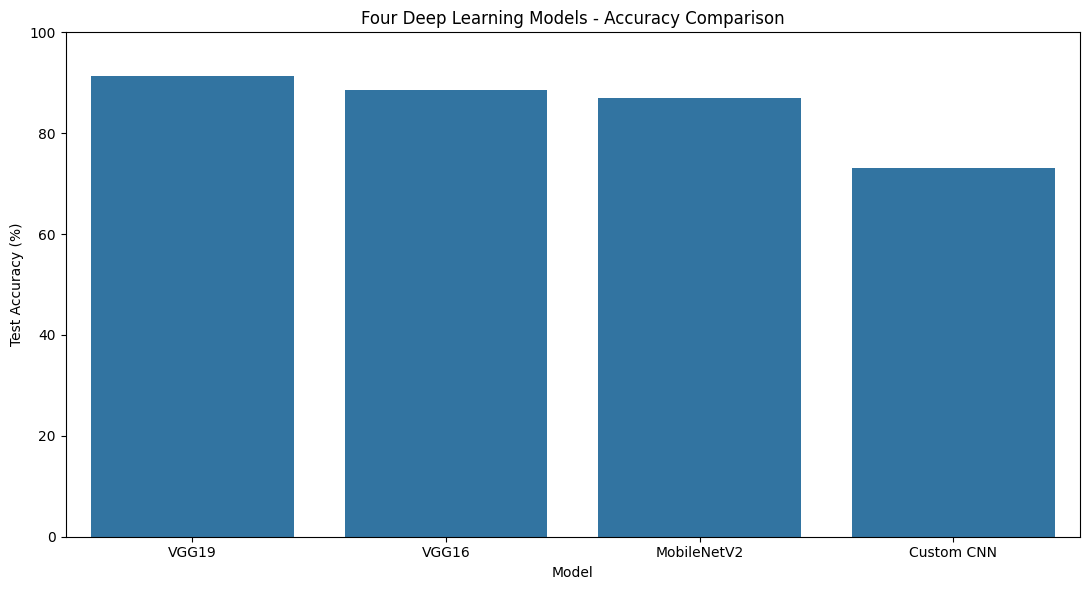

In [124]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.title("Four Deep Learning Models - Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_accuracy_comparison.png",
    dpi=300
)

plt.show()

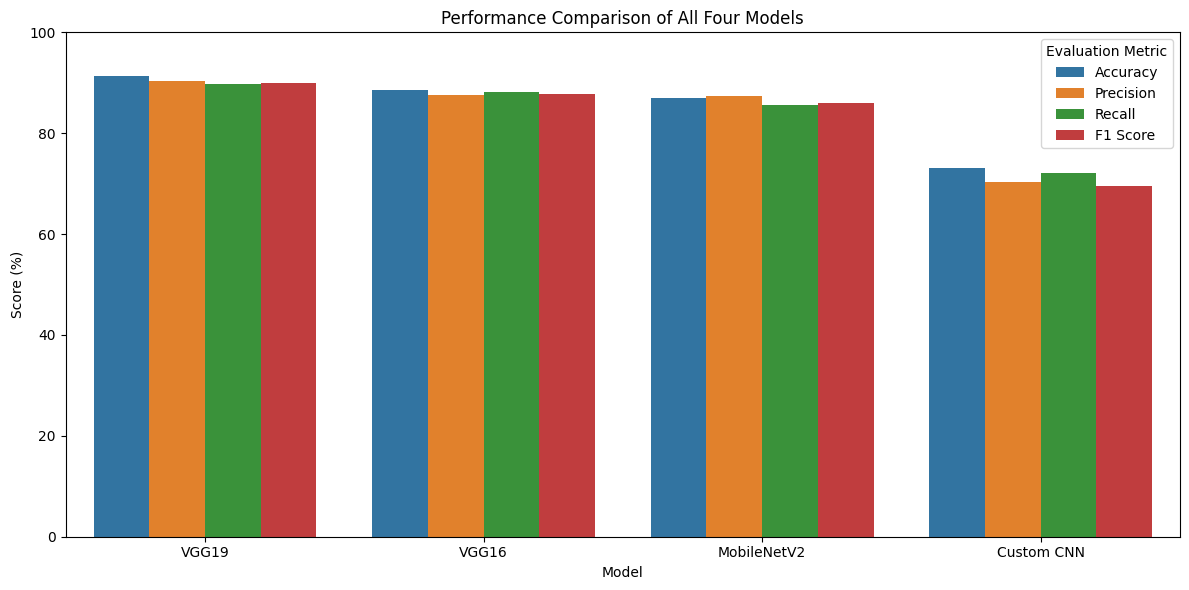

In [125]:
metrics_plot = comparison_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of All Four Models")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.legend(title="Evaluation Metric")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_metrics_comparison.png",
    dpi=300
)

plt.show()

In [126]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 6 REPORT")
print("=" * 55)

print("Model: VGG19")
print("Architecture: ImageNet pretrained")
print("Training: Feature extraction + fine-tuning")
print("Input size: 224 x 224 x 3")
print("Output classes:", NUM_CLASSES)

print("\nTEST PERFORMANCE")
print("-" * 40)

print(f"Accuracy:  {vgg19_accuracy * 100:.2f}%")
print(f"Precision: {vgg19_precision * 100:.2f}%")
print(f"Recall:    {vgg19_recall * 100:.2f}%")
print(f"F1 Score:  {vgg19_f1 * 100:.2f}%")

print("\nFINAL FOUR-MODEL COMPARISON")
print("-" * 40)

print(comparison_df.round(2).to_string(index=False))

print("\nSAVED MODEL")
print("-" * 40)

print("Model exists:", vgg19_final_path.exists())

print("\nSTAGE 6 COMPLETED!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 6 REPORT
Model: VGG19
Architecture: ImageNet pretrained
Training: Feature extraction + fine-tuning
Input size: 224 x 224 x 3
Output classes: 6

TEST PERFORMANCE
----------------------------------------
Accuracy:  91.29%
Precision: 90.43%
Recall:    89.76%
F1 Score:  89.93%

FINAL FOUR-MODEL COMPARISON
----------------------------------------
 Rank       Model  Accuracy  Precision  Recall  F1 Score
    1       VGG19     91.29      90.43   89.76     89.93
    2       VGG16     88.65      87.58   88.14     87.69
    3 MobileNetV2     87.07      87.29   85.67     86.01
    4  Custom CNN     73.09      70.27   72.12     69.62

SAVED MODEL
----------------------------------------
Model exists: True

STAGE 6 COMPLETED!


# Stage 7

In [127]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

model_files = {
    "Custom CNN": "cnn_model.keras",
    "MobileNetV2": "mobilenetv2_model.keras",
    "VGG16": "vgg16_model.keras",
    "VGG19": "vgg19_model.keras"
}

result_files = {
    "Custom CNN": "cnn_results.json",
    "MobileNetV2": "mobilenetv2_results.json",
    "VGG16": "vgg16_results.json",
    "VGG19": "vgg19_results.json"
}

results = []

for model_name, result_file in result_files.items():

    result_path = OUTPUT_DIR / result_file

    with open(result_path, "r") as f:
        data = json.load(f)

    model_path = MODEL_DIR / model_files[model_name]

    data["model_size_mb"] = (
        model_path.stat().st_size / (1024 * 1024)
        if model_path.exists() else None
    )

    results.append(data)

results_df = pd.DataFrame(results)

print("All four model results loaded!")
display(results_df)

All four model results loaded!


,model,accuracy,precision_macro,recall_macro,f1_macro,epochs_trained,model_size_mb,head_epochs,fine_tune_epochs,head_training_time_seconds,fine_tune_time_seconds,total_training_time_seconds
0,Custom CNN,0.730871,0.702656,0.721198,0.696180,30.0,4.924386,NaN,NaN,NaN,NaN,NaN
1,MobileNetV2,0.870712,0.872945,0.856695,0.860055,NaN,22.600205,15.0,7.0,542.598616,235.767230,778.365846
2,VGG16,0.886544,0.875811,0.881421,0.876939,NaN,111.760390,15.0,10.0,648.480156,438.780875,1087.261032
3,VGG19,0.912929,0.904312,0.897644,0.899344,NaN,150.031794,15.0,10.0,618.637876,495.674170,1114.312046


In [128]:
final_comparison = results_df[
    [
        "model",
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro",
        "model_size_mb"
    ]
].copy()

final_comparison.columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Model Size (MB)"
]

final_comparison = final_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

final_comparison.insert(
    0,
    "Rank",
    range(1, len(final_comparison) + 1)
)

print("FINAL MODEL PERFORMANCE")
display(final_comparison.round(3))

final_comparison.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

FINAL MODEL PERFORMANCE


,Rank,Model,Accuracy,Precision,Recall,F1 Score,Model Size (MB)
0,1,VGG19,0.913,0.904,0.898,0.899,150.032
1,2,VGG16,0.887,0.876,0.881,0.877,111.760
2,3,MobileNetV2,0.871,0.873,0.857,0.860,22.600
3,4,Custom CNN,0.731,0.703,0.721,0.696,4.924


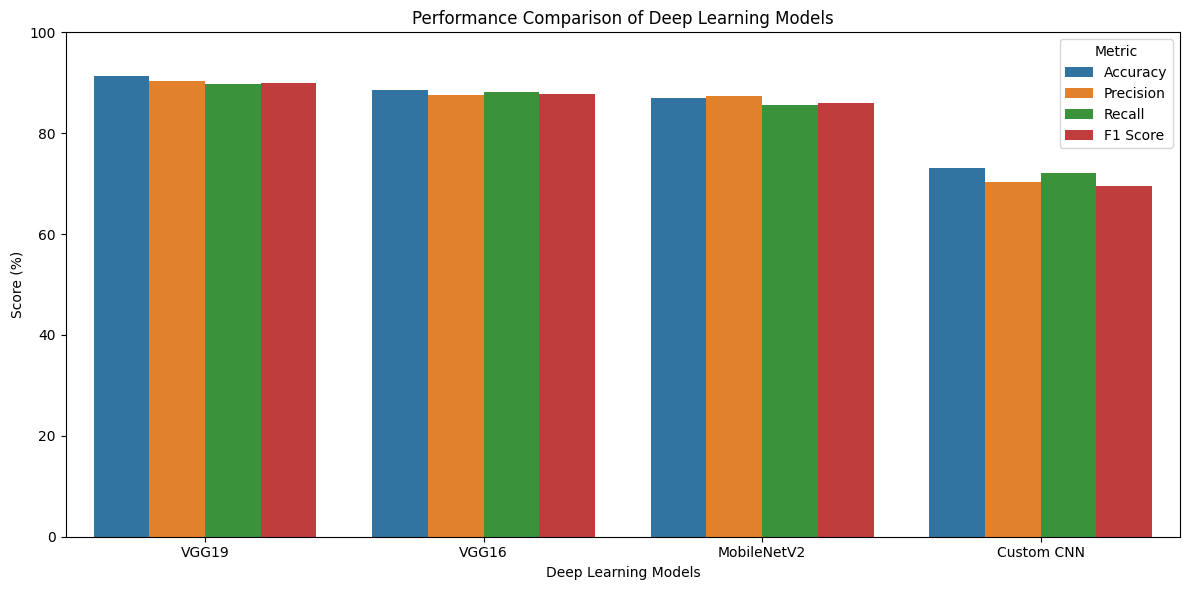

In [129]:
metrics_df = final_comparison.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

metrics_df["Score"] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Deep Learning Models")
plt.ylabel("Score (%)")
plt.xlabel("Deep Learning Models")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_performance_comparison.png",
    dpi=300
)

plt.show()

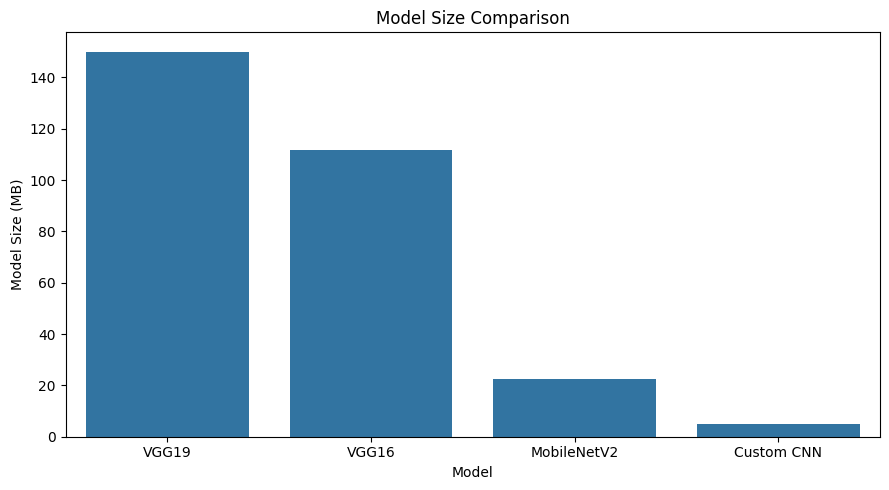

In [130]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="Model Size (MB)"
)

plt.title("Model Size Comparison")
plt.xlabel("Model")
plt.ylabel("Model Size (MB)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_size_comparison.png",
    dpi=300
)

plt.show()

,Model,Training Time (minutes)
0,Custom CNN,NaN
1,MobileNetV2,12.97
2,VGG16,18.12
3,VGG19,18.57


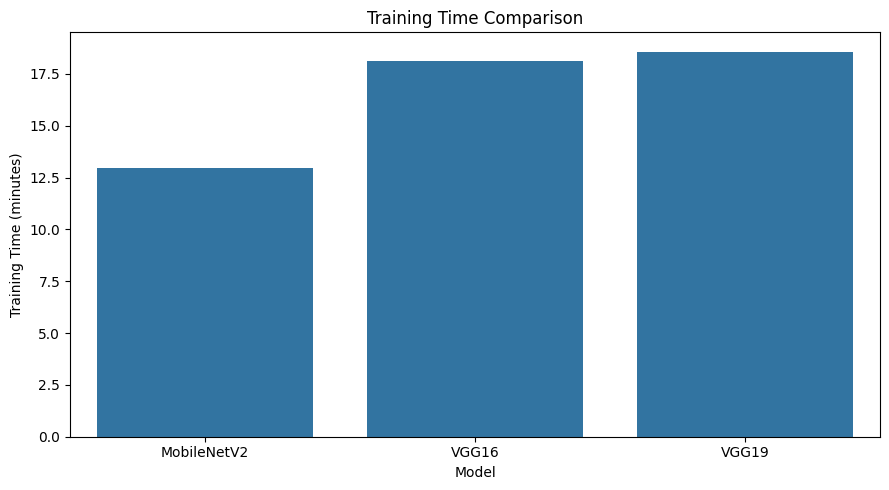

In [131]:
time_data = []

for _, row in results_df.iterrows():

    time_value = row.get(
        "total_training_time_seconds",
        None
    )

    time_data.append({
        "Model": row["model"],
        "Training Time (minutes)": (
            time_value / 60
            if pd.notna(time_value)
            else None
        )
    })

time_df = pd.DataFrame(time_data)

display(time_df.round(2))

time_df.to_csv(
    OUTPUT_DIR / "training_time_comparison.csv",
    index=False
)

available_times = time_df.dropna()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=available_times,
    x="Model",
    y="Training Time (minutes)"
)

plt.title("Training Time Comparison")
plt.ylabel("Training Time (minutes)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "training_time_comparison.png",
    dpi=300
)

plt.show()

In [132]:
best_model = final_comparison.iloc[0]

print("=" * 50)
print("BEST MODEL ANALYSIS")
print("=" * 50)

print("Best Model:", best_model["Model"])

print(
    f"Accuracy: {best_model['Accuracy'] * 100:.2f}%"
)

print(
    f"Precision: {best_model['Precision'] * 100:.2f}%"
)

print(
    f"Recall: {best_model['Recall'] * 100:.2f}%"
)

print(
    f"F1 Score: {best_model['F1 Score'] * 100:.2f}%"
)

print(
    f"Model Size: {best_model['Model Size (MB)']:.2f} MB"
)

BEST MODEL ANALYSIS
Best Model: VGG19
Accuracy: 91.29%
Precision: 90.43%
Recall: 89.76%
F1 Score: 89.93%
Model Size: 150.03 MB


In [133]:
conclusion = f"""
WASTE CLASSIFICATION - EXPERIMENTAL CONCLUSION

Four deep learning architectures were implemented and evaluated:
1. Custom CNN
2. MobileNetV2
3. VGG16
4. VGG19

All models were evaluated using the same test dataset.

The best performing model was {best_model['Model']}.

Test Accuracy: {best_model['Accuracy'] * 100:.2f}%
Macro Precision: {best_model['Precision'] * 100:.2f}%
Macro Recall: {best_model['Recall'] * 100:.2f}%
Macro F1 Score: {best_model['F1 Score'] * 100:.2f}%

The experiments demonstrate the effectiveness of transfer learning
for waste image classification.

The final model selection considers classification performance,
model size and computational requirements.
"""

with open(
    OUTPUT_DIR / "experimental_conclusion.txt",
    "w"
) as f:

    f.write(conclusion)

print(conclusion)


WASTE CLASSIFICATION - EXPERIMENTAL CONCLUSION

Four deep learning architectures were implemented and evaluated:
1. Custom CNN
2. MobileNetV2
3. VGG16
4. VGG19

All models were evaluated using the same test dataset.

The best performing model was VGG19.

Test Accuracy: 91.29%
Macro Precision: 90.43%
Macro Recall: 89.76%
Macro F1 Score: 89.93%

The experiments demonstrate the effectiveness of transfer learning
for waste image classification.

The final model selection considers classification performance,
model size and computational requirements.



In [134]:
print("=" * 55)
print("WASTE CLASSIFICATION - STAGE 7 REPORT")
print("=" * 55)

print("\nMODELS EVALUATED: 4")

print("\nFINAL RANKING")

print(
    final_comparison[
        ["Rank", "Model", "Accuracy", "F1 Score"]
    ].to_string(index=False)
)

print("\nBEST MODEL:", best_model["Model"])

print("\nGENERATED FILES:")

for file in OUTPUT_DIR.iterdir():

    if file.is_file() and (
        "comparison" in file.name
        or "conclusion" in file.name
    ):
        print("-", file.name)

print("\nSTAGE 7 COMPLETED!")
print("=" * 55)

WASTE CLASSIFICATION - STAGE 7 REPORT

MODELS EVALUATED: 4

FINAL RANKING
 Rank       Model  Accuracy  F1 Score
    1       VGG19  0.912929  0.899344
    2       VGG16  0.886544  0.876939
    3 MobileNetV2  0.870712  0.860055
    4  Custom CNN  0.730871  0.696180

BEST MODEL: VGG19

GENERATED FILES:
- cnn_mobilenet_comparison.csv
- cnn_mobilenet_comparison.png
- three_model_comparison.csv
- three_model_comparison.png
- final_model_comparison.csv
- final_accuracy_comparison.png
- final_metrics_comparison.png
- final_performance_comparison.png
- model_size_comparison.png
- training_time_comparison.csv
- training_time_comparison.png
- experimental_conclusion.txt

STAGE 7 COMPLETED!
